# HW1 Submission 

**Before you start, copy this notebook into your own workspace folder.** 

Follow this template for Questions 1, 2, 3 and the evidence section of Question 4, filling in your code in the cells indicated. Feel free to add as many cells as you want, but keep the same layout and do not remove the section headings.

For Question 2, you may draft each query in the `%sql` cell provided, then run it with `save_query`, which writes the `.sql` and `.csv` files you submit.
The written parts of Question 4 are submitted as a PDF; only the code that produced your numbers goes here.

Split your work into several cells rather than writing one long one, and add a short comment where a step is not obvious from the code itself. Do not write an essay in comments: a line explaining why you filtered something, or what a parsing step returns, is enough.

Everything you submit must be what this notebook produced. The files are written by the helpers provided below, not by hand, and the numbers in your Question 4 report must come from code in the evidence section. Do not edit a saved file afterwards, and do not report a number the notebook cannot reproduce. We check this.

Before you submit: restart the notebook and run it from beginning to end. It must complete without errors, and every output must be visible in the exported HTML.

## Load the data

Run the two cells below to load the data.

### Load the DataFrame

Run the cell below to read the data into `airbnb_df`. Use this for Questions 1, 3 and 4.

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.types import ArrayType, StringType, StructType, StructField

DATA_PATH = "/Volumes/94290_lab/course_data/airbnb/airbnb_1_12_parquet"
airbnb_df = spark.read.parquet(DATA_PATH)
print(f"rows: {airbnb_df.count():,}   columns: {len(airbnb_df.columns)}")
display(airbnb_df.limit(5))

rows: 2,098,880   columns: 50


name price image description category availability discount reviews ratings seller_info breadcrumbs location lat long guests pets_allowed description_items category_rating house_rules details highlights arrangement_details amenities images available_dates url final_url listing_title property_id listing_name location_details description_by_sections description_html location_details_html is_supperhost host_number_of_reviews host_rating hosts_year host_response_rate is_guest_favorite travel_details pricing_details total_price currency cancellation_policy property_number_of_reviews country postcode_map_url host_image host_details Rental unit in Fethiye · 2 bedrooms · 4 beds · 2 baths 2245.26 https://a0.muscache.com/pictures/miso/Hosting-872879841963747193/original/6abf41ab-92c6-49ad-97d6-56ce22a77164.jpeg It is a site with its own beach, and you have 7 pools Market. Restoran. There is Hama. Sun loungers and Beach Umbrella are free. 24 Hours Security Vardir Stays true null null 0 {"seller_id":"289319135","url":"https://www.airbnb.com/users/show/289319135"} Fethiye, Muğla, Turkey Fethiye, Muğla, Turkey 36.6744 29.101 4 false ["Entire rental unit","4 beds","2 baths"] [] ["Check-in after 3:00 p.m.","Checkout before 10:00 a.m.","4 guests maximum"] ["4 guests","2 bedrooms","4 beds","2 baths"] [{"name":"5-min walk to the beach","value":"This home is by Ceviz Beach."},{"name":"Dive right in","value":"This is one of the few places in the area with a pool."}] [{"name":"Bedroom","value":"1 double bed, 2 single beds, 1 couch"}] [{"group_name":"Scenic views","items":[{"name":"Pool view","value":"SYSTEM_POOL"}]},{"group_name":"Bedroom and laundry","items":[{"name":"Washer","value":"SYSTEM_WASHER"}]},{"group_name":"Entertainment","items":[{"name":"TV","value":"SYSTEM_TV"}]},{"group_name":"Family","items":[{"name":"High chair","value":"SYSTEM_HIGH_CHAIR"}]},{"group_name":"Heating and cooling","items":[{"name":"Air conditioning","value":"SYSTEM_SNOWFLAKE"}]},{"group_name":"Internet and office","items":[{"name":"Wifi","value":"SYSTEM_WI_FI"}]},{"group_name":"Kitchen and dining","items":[{"name":"Kitchen","value":"Space where guests can cook their own meals"},{"name":"Dishes and silverware","value":"Bowls, chopsticks, plates, cups, etc."}]},{"group_name":"Location features","items":[{"name":"Beach access – Beachfront","value":"Guests can enjoy a nearby beach"}]},{"group_name":"Outdoor","items":[{"name":"BBQ grill","value":"SYSTEM_GRILL"}]},{"group_name":"Parking and facilities","items":[{"name":"Free parking on premises","value":"SYSTEM_MAPS_CAR_RENTAL"},{"name":"Pool","value":"SYSTEM_POOL"}]},{"group_name":"Not included","items":[{"name":"Exterior security cameras on property","value":"SYSTEM_NO_SURVEILLANCE"},{"name":"Dryer","value":"SYSTEM_NO_DRYER"},{"name":"Essentials","value":"SYSTEM_NO_ESSENTIALS"},{"name":"Smoke alarm","value":"This place may not have a smoke detector. Reach out to the host with any questions."},{"name":"Carbon monoxide alarm","value":"This place may not have a carbon monoxide detector. Reach out to the host with any questions."},{"name":"Heating","value":"SYSTEM_NO_HEATER"},{"name":"Hot water","value":"SYSTEM_NO_HOT_WATER"}]}] ["https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/6abf41ab-92c6-49ad-97d6-56ce22a77164.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/4848d367-aab1-4342-9f8f-d70f5a127294.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/d337ca55-d529-4d40-a083-e5c7f74fda11.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/e0e7a836-21c1-4b4b-b107-1a87dd74131d.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/2272537e-e3b3-49c2-a985-f7dc23129bff.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/4b352df3-c364-43ab-8e76-e9b873374a20.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/3508a87

%md
### Load the SQL view

Run the cell below to make the same data available to the `%sql` cells as `airbnb_data`. Use this for Question 2.


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW airbnb_data AS
SELECT * FROM parquet.`/Volumes/94290_lab/course_data/airbnb/airbnb_1_12_parquet`;
SELECT * FROM airbnb_data LIMIT 5

name price image description category availability discount reviews ratings seller_info breadcrumbs location lat long guests pets_allowed description_items category_rating house_rules details highlights arrangement_details amenities images available_dates url final_url listing_title property_id listing_name location_details description_by_sections description_html location_details_html is_supperhost host_number_of_reviews host_rating hosts_year host_response_rate is_guest_favorite travel_details pricing_details total_price currency cancellation_policy property_number_of_reviews country postcode_map_url host_image host_details Rental unit in Fethiye · 2 bedrooms · 4 beds · 2 baths 2245.26 https://a0.muscache.com/pictures/miso/Hosting-872879841963747193/original/6abf41ab-92c6-49ad-97d6-56ce22a77164.jpeg It is a site with its own beach, and you have 7 pools Market. Restoran. There is Hama. Sun loungers and Beach Umbrella are free. 24 Hours Security Vardir Stays true null null 0 {"seller_id":"289319135","url":"https://www.airbnb.com/users/show/289319135"} Fethiye, Muğla, Turkey Fethiye, Muğla, Turkey 36.6744 29.101 4 false ["Entire rental unit","4 beds","2 baths"] [] ["Check-in after 3:00 p.m.","Checkout before 10:00 a.m.","4 guests maximum"] ["4 guests","2 bedrooms","4 beds","2 baths"] [{"name":"5-min walk to the beach","value":"This home is by Ceviz Beach."},{"name":"Dive right in","value":"This is one of the few places in the area with a pool."}] [{"name":"Bedroom","value":"1 double bed, 2 single beds, 1 couch"}] [{"group_name":"Scenic views","items":[{"name":"Pool view","value":"SYSTEM_POOL"}]},{"group_name":"Bedroom and laundry","items":[{"name":"Washer","value":"SYSTEM_WASHER"}]},{"group_name":"Entertainment","items":[{"name":"TV","value":"SYSTEM_TV"}]},{"group_name":"Family","items":[{"name":"High chair","value":"SYSTEM_HIGH_CHAIR"}]},{"group_name":"Heating and cooling","items":[{"name":"Air conditioning","value":"SYSTEM_SNOWFLAKE"}]},{"group_name":"Internet and office","items":[{"name":"Wifi","value":"SYSTEM_WI_FI"}]},{"group_name":"Kitchen and dining","items":[{"name":"Kitchen","value":"Space where guests can cook their own meals"},{"name":"Dishes and silverware","value":"Bowls, chopsticks, plates, cups, etc."}]},{"group_name":"Location features","items":[{"name":"Beach access – Beachfront","value":"Guests can enjoy a nearby beach"}]},{"group_name":"Outdoor","items":[{"name":"BBQ grill","value":"SYSTEM_GRILL"}]},{"group_name":"Parking and facilities","items":[{"name":"Free parking on premises","value":"SYSTEM_MAPS_CAR_RENTAL"},{"name":"Pool","value":"SYSTEM_POOL"}]},{"group_name":"Not included","items":[{"name":"Exterior security cameras on property","value":"SYSTEM_NO_SURVEILLANCE"},{"name":"Dryer","value":"SYSTEM_NO_DRYER"},{"name":"Essentials","value":"SYSTEM_NO_ESSENTIALS"},{"name":"Smoke alarm","value":"This place may not have a smoke detector. Reach out to the host with any questions."},{"name":"Carbon monoxide alarm","value":"This place may not have a carbon monoxide detector. Reach out to the host with any questions."},{"name":"Heating","value":"SYSTEM_NO_HEATER"},{"name":"Hot water","value":"SYSTEM_NO_HOT_WATER"}]}] ["https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/6abf41ab-92c6-49ad-97d6-56ce22a77164.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/4848d367-aab1-4342-9f8f-d70f5a127294.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/d337ca55-d529-4d40-a083-e5c7f74fda11.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/e0e7a836-21c1-4b4b-b107-1a87dd74131d.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/2272537e-e3b3-49c2-a985-f7dc23129bff.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/4b352df3-c364-43ab-8e76-e9b873374a20.jpeg","https://a0.muscache.com/im/pictures/miso/Hosting-872879841963747193/original/3508a87


## Question 1: Data Handling

PySpark only. No Pandas, NumPy or similar libraries.

Each question produces one table, saved with the `save_csv` helper below. Run the next cell once before you start.

In [0]:
import os

try:
    # inside a Databricks notebook this is the folder the notebook lives in
    notebook_path = dbutils.notebook.entry_point.getDbutils().notebook().getContext()\
        .notebookPath().get()
    OUT_DIR = "/Workspace" + notebook_path.rsplit("/", 1)[0]
except Exception:
    # Databricks Connect has no notebook path; dbutils raises "cluster_id is required"
    OUT_DIR = os.getcwd()
print(OUT_DIR)


def wait_for_file(path, timeout=30):
    """Wait until a written file is visible and non-empty. Do not modify."""
    import os, time
    start = time.time()
    while time.time() - start < timeout:
        if os.path.exists(path) and os.path.getsize(path) > 0:
            return path
        time.sleep(0.5)
    raise TimeoutError(f"{path} did not appear within {timeout}s")


def save_csv(sdf, file_name, out_dir=OUT_DIR):
    """Write a small result table to <out_dir>/<file_name>.csv. Do not modify this function."""
    import os, csv
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"{file_name}.csv")
    rows = sdf.collect()
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f, quoting=csv.QUOTE_MINIMAL)
        w.writerow(sdf.columns)
        for r in rows:
            w.writerow(["" if v is None else v for v in r])
        f.flush()
        os.fsync(f.fileno())
    wait_for_file(path)
    print(f"wrote {len(rows)} rows to {path}")
    return path


def save_query(query, file_name, out_dir=OUT_DIR):
    """Run a SQL query, save the query text as .sql and its result as .csv. Do not modify."""
    import os
    os.makedirs(out_dir, exist_ok=True)
    q = query.strip().rstrip(";")
    sql_path = os.path.join(out_dir, f"{file_name}.sql")
    with open(sql_path, "w", encoding="utf-8") as f:
        f.write(q + "\n")
        f.flush()
        os.fsync(f.fileno())
    wait_for_file(sql_path)
    result = spark.sql(q)
    save_csv(result, file_name)
    return result


def show_saved(file_name, out_dir=OUT_DIR):
    """Read back a saved CSV and display it. Do not modify."""
    import csv
    with open(f"{out_dir}/{file_name}.csv", newline="", encoding="utf-8") as f:
        rows = list(csv.reader(f))
    print(f"{len(rows) - 1} data rows")
    return spark.createDataFrame(rows[1:], rows[0])

/Workspace/Users/boaz.cohen@campus.technion.ac.il


%md
### Question 1a

The 15 properties with the largest gap between their highest and lowest category rating.

Your final DataFrame must be called `q1a`, with the columns already in the required order.

In [0]:
cat_schema = ArrayType(StructType([
    StructField("name", StringType()),
    StructField("value", StringType()),
]))

q1a_base = (
    airbnb_df
    .withColumn("overall_rating", F.col("ratings").cast("double")) # col 3
    .withColumn("cats_raw", F.from_json("category_rating", cat_schema))
    .withColumn("cats", F.transform("cats_raw", lambda c: F.struct(
        c["name"].alias("name"),
        F.regexp_replace(c["value"], ",", ".").try_cast("double").alias("value"), # def 1
    )))
)

q1a_base.select("property_id", "overall_rating", "cats").printSchema()

root
 |-- property_id: string (nullable = true)
 |-- overall_rating: double (nullable = true)
 |-- cats: array (nullable = true)
 |    |-- element: struct (containsNull = false)
 |    |    |-- name: string (nullable = true)
 |    |    |-- value: double (nullable = true)



In [0]:
q1a_work = ( ### col 1, 2?
    q1a_base
    .withColumn("cats_present", F.filter("cats", lambda c: c["name"].isNotNull() & c["value"].isNotNull())) # def 1 ### numeric rating?
    .where((F.col("overall_rating") >= 4.0) & (F.col("overall_rating") < 5.0)) # filter 1
    .where(F.exists("cats_present", lambda c: c["name"] == "Cleanliness")) # filter 2
    .where(F.col("property_id").isNotNull()) # filter 3
    .withColumn("num_categories", F.size("cats_present")) # col 4
    .withColumn("best_category_value", F.array_max(F.transform("cats_present", lambda c: c["value"]))) # col 6
    .withColumn("worst_category_value", F.array_min(F.transform("cats_present", lambda c: c["value"]))) # col 8
    .withColumn("best_category", F.array_min(F.transform(
        F.filter("cats_present", lambda c: c["value"] == F.col("best_category_value")),
        lambda c: c["name"]))) # col 5, def 3
    .withColumn("worst_category", F.array_min(F.transform(
        F.filter("cats_present", lambda c: c["value"] == F.col("worst_category_value")),
        lambda c: c["name"]))) # col 7, def 3
    .withColumn("rating_gap", F.col("best_category_value") - F.col("worst_category_value")) # col 9, def 2
)

In [0]:
q1a = (
    q1a_work
    .select(
        F.col("property_id").cast("string"),
        F.col("listing_name").cast("string"),
        F.col("overall_rating").cast("double"),
        F.col("num_categories").cast("int"),
        F.col("best_category").cast("string"),
        F.col("best_category_value").cast("double"),
        F.col("worst_category").cast("string"),
        F.col("worst_category_value").cast("double"),
        F.col("rating_gap").cast("double"),
    )
    .orderBy(
        F.desc("rating_gap"),
        F.desc("overall_rating"),
        F.asc("property_id"),
        F.desc("num_categories"),
        F.asc("best_category"),
    )
    .limit(15)
)

q1a.printSchema()
display(q1a)

root
 |-- property_id: string (nullable = true)
 |-- listing_name: string (nullable = true)
 |-- overall_rating: double (nullable = true)
 |-- num_categories: integer (nullable = true)
 |-- best_category: string (nullable = true)
 |-- best_category_value: double (nullable = true)
 |-- worst_category: string (nullable = true)
 |-- worst_category_value: double (nullable = true)
 |-- rating_gap: double (nullable = true)



property_id,listing_name,overall_rating,num_categories,best_category,best_category_value,worst_category,worst_category_value,rating_gap
41905528,"Entire home in Austin, Texas, United States",4.0,6,Accuracy,5.0,Cleanliness,1.0,4.0
19905528,"Entire condo in Saint-Raphaël, France",4.2,6,Location,5.0,Cleanliness,1.8,3.2
20471016,"Entire villa in Palm Springs, California, United States",4.83,6,Cleanliness,5.0,Communication,2.0,3.0
20471016,"Entire villa in Palm Springs, California, United States",4.83,6,Cleanliness,5.0,Communication,2.0,3.0
1148425447069509436,"Entire rental unit in Bandol, France",4.33,6,Check-in,5.0,Cleanliness,2.0,3.0
1148425447069509436,"Entire rental unit in Bandol, France",4.33,6,Check-in,5.0,Cleanliness,2.0,3.0
30131987,"Entire home in Atlanta, Georgia, United States",4.33,6,Check-in,5.0,Location,2.0,3.0
899943459145538731,"Room in Mexico City, Mexico",4.33,6,Check-in,5.0,Communication,2.0,3.0
991215126247903607,"Entire cottage in Cumbria, United Kingdom",4.33,6,Location,5.0,Check-in,2.0,3.0
1274812813940936199,"Entire rental unit in Cali, Colombia",4.25,6,Cleanliness,4.8,Location,1.8,3.0


In [0]:
save_csv(q1a, "q1a")
display(show_saved("q1a"))

wrote 15 rows to /Workspace/Users/boaz.cohen@campus.technion.ac.il/q1a.csv
15 data rows


property_id,listing_name,overall_rating,num_categories,best_category,best_category_value,worst_category,worst_category_value,rating_gap
41905528,"Entire home in Austin, Texas, United States",4.0,6,Accuracy,5.0,Cleanliness,1.0,4.0
19905528,"Entire condo in Saint-Raphaël, France",4.2,6,Location,5.0,Cleanliness,1.8,3.2
20471016,"Entire villa in Palm Springs, California, United States",4.83,6,Cleanliness,5.0,Communication,2.0,3.0
20471016,"Entire villa in Palm Springs, California, United States",4.83,6,Cleanliness,5.0,Communication,2.0,3.0
1148425447069509436,"Entire rental unit in Bandol, France",4.33,6,Check-in,5.0,Cleanliness,2.0,3.0
1148425447069509436,"Entire rental unit in Bandol, France",4.33,6,Check-in,5.0,Cleanliness,2.0,3.0
30131987,"Entire home in Atlanta, Georgia, United States",4.33,6,Check-in,5.0,Location,2.0,3.0
899943459145538731,"Room in Mexico City, Mexico",4.33,6,Check-in,5.0,Communication,2.0,3.0
991215126247903607,"Entire cottage in Cumbria, United Kingdom",4.33,6,Location,5.0,Check-in,2.0,3.0
1274812813940936199,"Entire rental unit in Cali, Colombia",4.25,6,Cleanliness,4.8,Location,1.8,3.0


### Question 1b

The 25 properties with the most beds that do not offer TV and allow check-in at 2:00 PM, among properties priced from 100 to 400 US dollars per night, both ends included, with 4 or more beds.

Your final DataFrame must be called `q1b`, with the columns already in the required order.

In [0]:
q1b_price = airbnb_df.withColumn(
    "price_usd",
    F.when(F.col("currency") == "USD", F.col("price").cast("double"))
     .when(F.col("currency") == "EUR", F.col("price").cast("double") * 1.08)
) # def 4, col 3

In [0]:
amen_item = StructType([StructField("name", StringType()), StructField("value", StringType())])
amen_schema = ArrayType(StructType([
    StructField("group_name", StringType()),
    StructField("items", ArrayType(amen_item)),
])) # def 2

NOT_INCLUDED_GROUPS = ["Not included", "Nicht enthalten", "Non inclus"]
MISSING_VALUE_RE = (
    r"^SYSTEM_NO_|^SYSTEM_OFFLINE$"
    r"|^There is no .* on the (property|bedroom door)\.$|^This place may not have a |^Host has indicated (that )?no "
    r"|^Es gibt kein|gibt es möglicherweise kein|hat angegeben, dass kein"
) # def 1


def is_available(group, item):
    missing = (F.coalesce(group["group_name"].isin(NOT_INCLUDED_GROUPS), F.lit(False))
               | F.coalesce(item["value"].rlike(MISSING_VALUE_RE), F.lit(False)))
    return ~missing


q1b_amen = (
    q1b_price
    .withColumn("amen_groups", F.from_json("amenities", amen_schema))
    # flatten groups into one list of items per row, tagging each item as available or not
    .withColumn("amen_items", F.flatten(F.transform("amen_groups", lambda g: F.transform(
        g["items"], lambda i: F.struct(
            i["name"].alias("name"),
            i["value"].alias("value"),
            is_available(g, i).alias("available"),
        )))))
    .withColumn("amen_available", F.filter("amen_items", lambda i: i["available"])) # def 1
    .withColumn("num_amenities", F.coalesce(F.size("amen_available"), F.lit(0))) # def 2, col 5
    .withColumn("has_tv", F.coalesce(F.exists("amen_available", lambda i: i["value"] == "SYSTEM_TV"), F.lit(False))) # filter 2
)

In [0]:
BEDS_RE = r"^(\d+) ([A-Za-z ]+ )?beds?$"

q1b_beds = (# def 3
    q1b_amen
    .withColumn("details_arr", F.from_json("details", ArrayType(StringType())))
    .withColumn("beds_entry", F.get(F.filter("details_arr", lambda d: d.rlike(BEDS_RE)), 0))
    .withColumn("num_beds", F.regexp_extract("beds_entry", BEDS_RE, 1).try_cast("int")) # col 4 
)

In [0]:
# def 5
def normalise_rule(c): 
    """For parsing only: narrow/no-break spaces -> space, lower case, "p.m." -> "pm"."""
    c = F.regexp_replace(c, "[\u202f\u00a0]", " ")
    return F.regexp_replace(F.lower(c), r"([ap])\.m\.", "$1m")


TIME = r"(\d{1,2}):(\d{2}) ?(am|pm)?"
AFTER_RE = rf"^check-in after {TIME}$"
RANGE_RE = rf"^check-in: {TIME} ?[-–] ?{TIME}$"
FLEX_RE = r"^flexible check-in$"
CHECKIN_RE = f"{AFTER_RE}|{RANGE_RE}|{FLEX_RE}"


def to_minutes(rule, regex, first_group):
    """Minutes after midnight from the hour, minute and am/pm groups (24-hour clock when am/pm is missing)."""
    hour = F.regexp_extract(rule, regex, first_group).try_cast("int")
    minute = F.regexp_extract(rule, regex, first_group + 1).try_cast("int")
    ampm = F.regexp_extract(rule, regex, first_group + 2)
    hour = F.when(ampm == "pm", hour % 12 + 12).when(ampm == "am", hour % 12).otherwise(hour)
    return hour * 60 + minute


TWO_PM = 14 * 60

q1b_checkin = (
    q1b_beds
    .withColumn("rules_arr", F.from_json("house_rules", ArrayType(StringType())))
    .withColumn("check_in_rule", F.get(F.filter("rules_arr", lambda r: normalise_rule(r).rlike(CHECKIN_RE)), 0)) # col 6
    .withColumn("ci_norm", normalise_rule(F.col("check_in_rule")))
    .withColumn("ci_start", F.coalesce(to_minutes(F.col("ci_norm"), AFTER_RE, 1),
                                       to_minutes(F.col("ci_norm"), RANGE_RE, 1)))
    .withColumn("ci_end", to_minutes(F.col("ci_norm"), RANGE_RE, 4))
    .withColumn(
        "allows_2pm",
        F.when(F.col("ci_norm").rlike(FLEX_RE), True)
         .when(F.col("ci_end").isNull(), F.col("ci_start") <= TWO_PM)
         .when(F.col("ci_end") > F.col("ci_start"),
               (F.col("ci_start") <= TWO_PM) & (F.col("ci_end") >= TWO_PM))
         .otherwise((F.col("ci_start") <= TWO_PM) | (F.col("ci_end") >= TWO_PM))
    )
)

In [0]:
# null price_usd / num_beds / allows_2pm fail these comparisons, so those rows are excluded
q1b = (
    q1b_checkin
    .where(F.col("price_usd").between(100, 400)) # filter 1
    .where(~F.col("has_tv")) # filter 2
    .where(F.col("allows_2pm")) # filter 3 
    .where(F.col("num_beds") >= 4) # filter 4
    .select(
        F.col("property_id").cast("string"), 
        F.col("listing_name").cast("string"),
        F.col("price_usd").cast("double"),
        F.col("num_beds").cast("int"),
        F.col("num_amenities").cast("int"),
        F.col("check_in_rule").cast("string"),
    )
    .orderBy(
        F.desc("num_beds"),
        F.asc("price_usd"),
        F.desc("num_amenities"),
        F.asc("property_id"),
        F.asc("listing_name"),
        F.asc("check_in_rule"),
    )
    .limit(25)
)

q1b.printSchema()
display(q1b)

root
 |-- property_id: string (nullable = true)
 |-- listing_name: string (nullable = true)
 |-- price_usd: double (nullable = true)
 |-- num_beds: integer (nullable = true)
 |-- num_amenities: integer (nullable = false)
 |-- check_in_rule: string (nullable = true)



property_id,listing_name,price_usd,num_beds,num_amenities,check_in_rule
1176805984728024335,"Entire home in Blewitt Springs, Australia",362.0,72,32,Check-in after 9:00 a.m.
1043944767320230330,"Shipping container in Sóc Sơn, Vietnam",350.53,52,25,Check-in: 2:00 PM - 6:00 PM
1352206417712905091,"Entire home in Fukuchiyama, Japan",367.0,50,38,Check-in after 2:00 p.m.
29894071,"Room in Semporna, Malaysia",126.0,43,26,Check-in after 2:00 PM
40332116,"Entire guest suite in Ulaanbaatar, Mongolia",180.0,36,19,Flexible check-in
38406871,"Private room in resort in Manú Province, Peru",180.0,36,11,Flexible check-in
1331957835792519515,"Entire cabin in Santa Marta, Colombia",244.0,36,37,Check-in after 2:00 p.m.
45006749,"Entire rental unit in Kisoroszi, Hungary",119.38,32,12,Check-in: 2:00 PM - 6:00 PM
1293149159757518693,"Room in Cartagena de Indias, Colombia",159.0,32,38,Flexible check-in
1083286479232816527,"Entire home in Biritiba Mirim, Brazil",159.5,30,6,Check-in: 8:00 AM - 8:00 PM


In [0]:
save_csv(q1b, "q1b")

# read the saved file back and show it, so what you see is what will be submitted
display(show_saved("q1b"))

wrote 25 rows to /Workspace/Users/boaz.cohen@campus.technion.ac.il/q1b.csv
25 data rows


property_id,listing_name,price_usd,num_beds,num_amenities,check_in_rule
1176805984728024335,"Entire home in Blewitt Springs, Australia",362.0,72,32,Check-in after 9:00 a.m.
1043944767320230330,"Shipping container in Sóc Sơn, Vietnam",350.53,52,25,Check-in: 2:00 PM - 6:00 PM
1352206417712905091,"Entire home in Fukuchiyama, Japan",367.0,50,38,Check-in after 2:00 p.m.
29894071,"Room in Semporna, Malaysia",126.0,43,26,Check-in after 2:00 PM
40332116,"Entire guest suite in Ulaanbaatar, Mongolia",180.0,36,19,Flexible check-in
38406871,"Private room in resort in Manú Province, Peru",180.0,36,11,Flexible check-in
1331957835792519515,"Entire cabin in Santa Marta, Colombia",244.0,36,37,Check-in after 2:00 p.m.
45006749,"Entire rental unit in Kisoroszi, Hungary",119.38,32,12,Check-in: 2:00 PM - 6:00 PM
1293149159757518693,"Room in Cartagena de Indias, Colombia",159.0,32,38,Flexible check-in
1083286479232816527,"Entire home in Biritiba Mirim, Brazil",159.5,30,6,Check-in: 8:00 AM - 8:00 PM


## Question 2: SQL Queries

Write each query as a string in the cell provided, then run it with `save_query`, which runs the query, saves the text as `q2a.sql` or `q2b.sql`, and saves the result as `q2a.csv` or `q2b.csv`.

Each query must be a single statement that runs on its own and returns exactly the columns listed, with those names, in that order. Use `WITH` clauses for intermediate steps.

You can develop your query in a `%sql` cell first if you prefer the editor, then paste the finished query into the string below. If `airbnb_data` is not found, re-run the setup cell at the top of the notebook.

### Question 2a

The 10 hosts with the highest average rating across their great value listings.


In [0]:
q2a_query = """
WITH parsed_listings AS (
    SELECT
        CAST(get_json_object(seller_info, '$.seller_id') AS STRING) AS seller_id,
        CAST(property_id AS STRING) AS property_id,
        TRY_CAST(ratings AS DOUBLE) AS overall_rating,
        TRY_CAST(property_number_of_reviews AS DOUBLE) AS num_reviews,
        from_json(
            category_rating,
            'ARRAY<STRUCT<name: STRING, value: STRING>>'
        ) AS categories
    FROM airbnb_data
), great_value_listings AS (
    SELECT seller_id, property_id, overall_rating, num_reviews
    FROM parsed_listings
    WHERE seller_id IS NOT NULL
      AND property_id IS NOT NULL
      AND overall_rating IS NOT NULL
      -- Test the array in place so repeated category entries cannot multiply rows.
      AND exists(
          categories,
          c -> c.name = 'Value'
               AND TRY_CAST(replace(c.value, ',', '.') AS DOUBLE) >= 4.8
      )
), host_averages AS (
    SELECT
        seller_id,
        CAST(COUNT(DISTINCT property_id) AS INT) AS num_listings,
        AVG(overall_rating) AS avg_rating,
        AVG(num_reviews) AS avg_reviews
    FROM great_value_listings
    GROUP BY seller_id
    -- Count distinct properties, but average all qualifying records.
    HAVING COUNT(DISTINCT property_id) >= 3
       AND AVG(overall_rating) < 5.0
)
SELECT
    seller_id,
    num_listings,
    CAST(ROUND(avg_rating, 3) AS DOUBLE) AS avg_rating,
    CAST(ROUND(avg_reviews, 3) AS DOUBLE) AS avg_reviews
FROM host_averages
ORDER BY avg_rating DESC, avg_reviews DESC, num_listings DESC, seller_id ASC
LIMIT 10
"""


In [0]:
q2a = save_query(q2a_query, "q2a")

# Read back the generated CSV so the displayed table matches the submission.
display(show_saved("q2a"))


wrote 10 rows to /Workspace/Users/boaz.cohen@campus.technion.ac.il/q2a.csv
10 data rows


seller_id,num_listings,avg_rating,avg_reviews
82290182,6,4.999,39.5
78226007,6,4.999,8.0
37831349,4,4.998,384.333
209325686,4,4.998,173.333
144817491,3,4.998,146.0
338409960,3,4.998,137.0
4400003,4,4.998,124.5
110287362,3,4.998,97.5
12096218,3,4.998,77.0
356561715,4,4.998,76.0


### Question 2b

The 10 superhosts whose listings are the most expensive on average.



In [0]:
q2b_query = """
WITH parsed_listings AS (
    SELECT
        CAST(get_json_object(seller_info, '$.seller_id') AS STRING) AS seller_id,
        CAST(property_id AS STRING) AS property_id,
        TRY_CAST(price AS DOUBLE) AS listing_price,
        TRY_CAST(is_supperhost AS BOOLEAN) AS is_superhost
    FROM airbnb_data
    WHERE property_id IS NOT NULL
), superhosts AS (
    -- Establish host status before filtering prices, including null/out-of-range prices.
    SELECT seller_id
    FROM parsed_listings
    WHERE seller_id IS NOT NULL
    GROUP BY seller_id
    HAVING bool_or(is_superhost)
), eligible_listings AS (
    SELECT listings.seller_id, listings.property_id, listings.listing_price
    FROM parsed_listings AS listings
    LEFT SEMI JOIN superhosts
        ON listings.seller_id = superhosts.seller_id
    -- Use the original price field, without currency conversion.
    WHERE listings.listing_price BETWEEN 100 AND 2000
), host_prices AS (
    SELECT
        seller_id,
        CAST(COUNT(DISTINCT property_id) AS INT) AS num_listings,
        AVG(listing_price) AS avg_price,
        MIN(listing_price) AS min_price
    FROM eligible_listings
    GROUP BY seller_id
    HAVING COUNT(DISTINCT property_id) > 1
)
SELECT
    seller_id,
    num_listings,
    CAST(ROUND(avg_price, 3) AS DOUBLE) AS avg_price,
    CAST(ROUND(min_price, 3) AS DOUBLE) AS min_price
FROM host_prices
ORDER BY avg_price DESC, num_listings DESC, seller_id ASC
LIMIT 10
"""


In [0]:
q2b = save_query(q2b_query, "q2b")

# Read back the generated CSV so the displayed table matches the submission.
display(show_saved("q2b"))


wrote 10 rows to /Workspace/Users/boaz.cohen@campus.technion.ac.il/q2b.csv
10 data rows


seller_id,num_listings,avg_price,min_price
35491667,4,1959.92,1959.92
231021347,2,1942.82,1892.0
572649285,2,1941.36,1924.0
71842368,3,1934.087,1921.0
157999191,5,1929.968,1853.0
419863661,2,1910.58,1907.16
15617507,2,1909.0,1880.0
1385332,2,1906.125,1895.65
92494059,2,1900.0,1800.0
26377263,5,1898.797,1761.0


## Question 3: Data Exploration & Visualization

Exploration and filtering in PySpark only. Charts may use matplotlib, seaborn, plotly or a dashboarding tool; if you use an external tool, the code that produced the aggregated data must still appear here.

At most 2 charts per section. A figure made of several related subplots counts as one chart, as long as the subplots answer the same question together, for example the same comparison across a few categories, or one distribution split by group. Say in your explanation why the subplots belong together. Unrelated subplots packed into one figure count separately.

For each chart, state the filtering or sampling you applied and how many rows were left, and keep your explanation to at most 3 sentences.

### Question 3a

How do the textual reviews of highly rated properties differ from those of poorly rated ones?

In [0]:
# 3a setup: rating groups. ratings == 0 is the placeholder for "no reviews yet", so it is never "poorly rated".
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql.types import ArrayType, StringType

# the review-text queries below can take longer than the 30 s default query timeout of a serverless Connect session
spark.conf.set("spark.databricks.execution.timeout", "900")

HIGH, LOW = 4.9, 4.0   # high: >= 4.9 (about the top half of rated rows); low: < 4.0 (below Airbnb's usual range)
MIN_REVIEWS = 3        # a rating built on 1-2 reviews is one guest's opinion, so both groups need >= 3 texts


def hash_sample(df, fraction):
    """Deterministic sample: keep a row when a hash of its content falls below `fraction` (a Column or number).
    Used instead of sample()/sampleBy(), whose result changes between runs on serverless."""
    u = (F.abs(F.xxhash64("url", "property_id", "reviews")) % 1_000_000) / 1_000_000
    return df.where(u < fraction)


a3 = (
    airbnb_df
    .withColumn("rating", F.col("ratings").try_cast("double"))
    .withColumn("rev", F.from_json("reviews", ArrayType(StringType())))
    .withColumn("n_text_reviews", F.coalesce(F.size("rev"), F.lit(0)))
    .where(F.col("rating") > 0)
)
a3_band = (F.when(F.col("rating") < 3.5, "1: <3.5").when(F.col("rating") < 4.0, "2: 3.5-4.0")
            .when(F.col("rating") < 4.5, "3: 4.0-4.5").when(F.col("rating") < 4.8, "4: 4.5-4.8")
            .when(F.col("rating") < 4.9, "5: 4.8-4.9").otherwise("6: >=4.9"))
a3 = a3.withColumn("band", a3_band)

# Why MIN_REVIEWS: low ratings mostly belong to listings with very few reviews
(a3.groupBy("band")
   .agg(F.count("*").alias("rows"),
        F.percentile_approx("n_text_reviews", 0.5).alias("median_text_reviews"),
        F.round(F.avg((F.col("n_text_reviews") < MIN_REVIEWS).cast("double")), 3).alias(f"share_with_<{MIN_REVIEWS}_reviews"))
   .orderBy("band").show())

+----------+------+-------------------+---------------------+
|      band|  rows|median_text_reviews|share_with_<3_reviews|
+----------+------+-------------------+---------------------+
|   1: <3.5| 25953|                  1|                0.784|
|2: 3.5-4.0| 17156|                  4|                0.217|
|3: 4.0-4.5|145324|                  7|                0.212|
|4: 4.5-4.8|430449|                 23|                 0.05|
|5: 4.8-4.9|340459|                 24|                  0.0|
|  6: >=4.9|939904|                 13|                 0.23|
+----------+------+-------------------+---------------------+



In [0]:
# 3a groups and sample: keep every low row, sample the (much larger) high group down to the same number of rows
a3_groups = (
    a3.where(F.col("n_text_reviews") >= MIN_REVIEWS)
    .withColumn("group", F.when(F.col("rating") >= HIGH, "high").when(F.col("rating") < LOW, "low"))
    .where(F.col("group").isNotNull())
)
a3_sizes = {r["group"]: r["count"] for r in a3_groups.groupBy("group").count().collect()}
a3_sample = hash_sample(a3_groups, F.when(F.col("group") == "high", min(1.0, a3_sizes["low"] / a3_sizes["high"]))
                                    .otherwise(1.0))

# one row per review text: the unit of analysis changes from listing to review on purpose (no listing is counted twice)
STOP = set("""a an the and or of to in on at for from with by is are was were be been being it its this that these those
there here we our us you your i me my he she him her his they them their as so if then than too very just also all any
some can could would will should had has have do did does done get got one two us really much more most place stay stayed
""".split())  # negations and "but" are kept on purpose: they carry the complaint
a3_reviews = (
    a3_sample.select("group", "property_id", F.explode("rev").alias("text"))
    .withColumn("tok", F.filter(F.split(F.regexp_replace(F.lower(F.regexp_replace("text", r"<br\s*/?>", " ")),
                                                         r"[^a-z']+", " "), " "), lambda t: F.length(t) > 0))
)
stop_arr = F.array(*[F.lit(w) for w in sorted(STOP)])
a3_terms = (
    a3_reviews
    # unigrams that are not stopwords, plus bigrams that are not two stopwords ("hot water", "not clean")
    .withColumn("uni", F.filter("tok", lambda t: ~F.array_contains(stop_arr, t) & (F.length(t) >= 3)))
    .withColumn("bi", F.filter(
        F.transform(F.sequence(F.lit(0), F.greatest(F.size("tok") - 2, F.lit(-1))),
                    lambda i: F.array(F.get("tok", i), F.get("tok", i + 1))),
        lambda b: ~(F.array_contains(stop_arr, b[0]) & F.array_contains(stop_arr, b[1]))))
    .withColumn("terms", F.array_distinct(F.concat("uni", F.transform("bi", lambda b: F.concat_ws(" ", b)))))
)
a3_n = {r["group"]: (r["rows"], r["reviews"]) for r in
        a3_reviews.groupBy("group").agg(F.countDistinct("property_id").alias("props"), F.count("*").alias("reviews"))
        .join(a3_sample.groupBy("group").agg(F.count("*").alias("rows")), "group").collect()}
print(f"groups before sampling (rows): {a3_sizes}")
for g, (rows, revs) in a3_n.items():
    print(f"{g}: {rows:,} listing rows, {revs:,} review texts after sampling")

groups before sampling (rows): {'low': 19035, 'high': 723614}
low: 19,035 listing rows, 116,331 review texts after sampling
high: 19,009 listing rows, 324,535 review texts after sampling


In [0]:
# 3a word statistics: share of reviews in each group that contain the term, and a log odds ratio with its z-score
N_LOW, N_HIGH = a3_n["low"][1], a3_n["high"][1]
MIN_DOCS = 150  # terms must appear in at least this many reviews overall to be ranked

a3_stats = (
    a3_terms.select("group", F.explode("terms").alias("term"))
    .groupBy("term").pivot("group", ["low", "high"]).count().na.fill(0)
    .where(F.col("low") + F.col("high") >= MIN_DOCS)
    .withColumn("p_low", F.col("low") / N_LOW)
    .withColumn("p_high", F.col("high") / N_HIGH)
    # log odds ratio (+0.5 smoothing) and its standard error: z ranks terms by how reliably they separate the groups
    .withColumn("log_or", F.log((F.col("low") + 0.5) / (N_LOW - F.col("low") + 0.5))
                          - F.log((F.col("high") + 0.5) / (N_HIGH - F.col("high") + 0.5)))
    .withColumn("z", F.col("log_or") / F.sqrt(1 / (F.col("low") + 0.5) + 1 / (N_LOW - F.col("low") + 0.5)
                                             + 1 / (F.col("high") + 0.5) + 1 / (N_HIGH - F.col("high") + 0.5)))
)
TOP_K = 15
from pyspark.sql import Window
# both top-K lists in one query (the text pipeline is expensive, so it should run once)
a3_top = (
    a3_stats
    .withColumn("rank_low", F.row_number().over(Window.orderBy(F.desc("z"), "term")))
    .withColumn("rank_high", F.row_number().over(Window.orderBy("z", "term")))
    .where((F.col("rank_low") <= TOP_K) | (F.col("rank_high") <= TOP_K))
    .withColumn("side", F.when(F.col("rank_low") <= TOP_K, "low").otherwise("high"))
    .toPandas()
    .sort_values(["side", "z"], ascending=[False, False])
)
print(a3_top[["side", "term", "low", "high", "p_low", "p_high", "log_or", "z"]].round(4).to_string(index=False))

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


side             term   low   high  p_low  p_high  log_or        z
 low              not 31672  24080 0.2723  0.0742  1.5407 164.0158
 low              but 30051  35647 0.2583  0.1098  1.0377 118.7323
 low          was not  7145   2236 0.0614  0.0069  2.2440  91.6614
 low             good 23983  34432 0.2062  0.1061  0.7830  84.9253
 low            price  6563   3216 0.0564  0.0099  1.7873  81.9655
 low              bad  5402   1358 0.0464  0.0042  2.4498  80.1889
 low          because  8272   6454 0.0711  0.0199  1.3278  78.2118
 low           is not  5765   2693 0.0496  0.0083  1.8295  77.5279
 low          did not  5889   2926 0.0506  0.0090  1.7682  77.2694
 low         bathroom  9247   8339 0.0795  0.0257  1.1861  76.4746
 low          however  5386   2356 0.0463  0.0073  1.8928  75.8863
 low            dirty  7323    337 0.0629  0.0010  4.1672  74.7036
 low         cleaning  4649   1616 0.0400  0.0050  2.1182  72.8374
 low             room 15531  21024 0.1335  0.0648  0.7995  71.

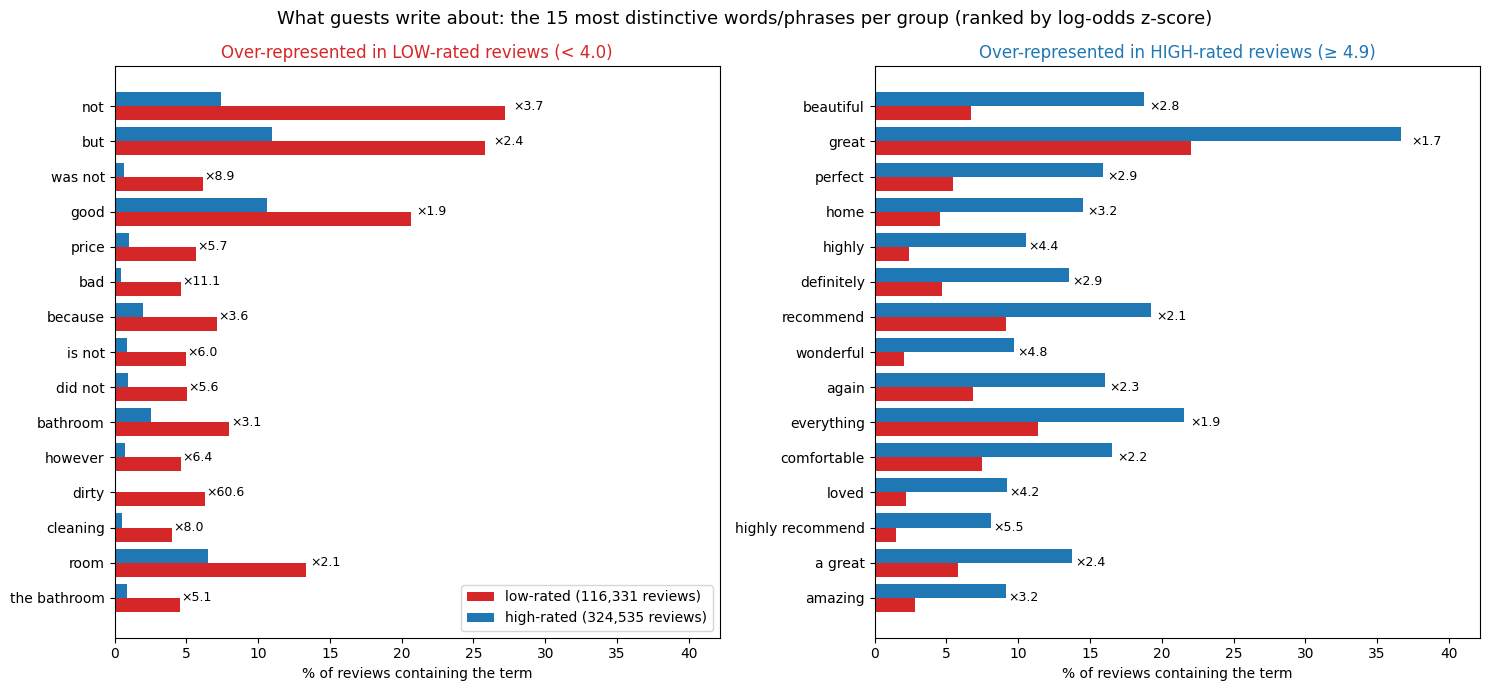

In [0]:
# 3a chart 1: the terms that most separate low- from high-rated listings' reviews
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, side, color, title in [(axes[0], "low", "#d62728", f"Over-represented in LOW-rated reviews (< {LOW})"),
                               (axes[1], "high", "#1f77b4", f"Over-represented in HIGH-rated reviews (≥ {HIGH})")]:
    d = a3_top[a3_top.side == side].sort_values("z", key=abs)
    y = np.arange(len(d))
    ax.barh(y - 0.2, d.p_low * 100, height=0.4, color="#d62728", label=f"low-rated ({N_LOW:,} reviews)")
    ax.barh(y + 0.2, d.p_high * 100, height=0.4, color="#1f77b4", label=f"high-rated ({N_HIGH:,} reviews)")
    ax.set_yticks(y, d.term)
    for yi, (_, r) in zip(y, d.iterrows()):
        ratio = r.p_low / r.p_high if side == "low" else r.p_high / r.p_low
        ax.text(max(r.p_low, r.p_high) * 100 * 1.02, yi, f"×{ratio:.1f}", va="center", fontsize=9)
    ax.set_xlabel("% of reviews containing the term")
    ax.set_title(title, color=color)
    ax.set_xlim(0, a3_top[["p_low", "p_high"]].values.max() * 100 * 1.15)
axes[0].legend(loc="lower right")
fig.suptitle("What guests write about: the 15 most distinctive words/phrases per group (ranked by log-odds z-score)", fontsize=13)
fig.tight_layout()
plt.show()

**Assumptions and filtering (3a):**

- What counts as highly rated / poorly rated: highly rated listings have ratings ≥ 4.9, while poorly rated listings have ratings below 4.0; these thresholds separate clearly positive and negative experiences, and ratings of 0 are excluded because they indicate no reviews.
- Filtering or sampling applied, and rows remaining: Both groups require at least three text reviews to reduce reliance on very limited feedback, since 78.4% of listings rated below 3.5 have fewer than three; all 19,035 qualifying low-rated rows are retained, while a repeatable hash sample reduces the 723,614 high-rated rows to approximately the same size
- Size of each group: Low-rated: 19,035 listing rows and 116,331 review texts; high-rated: 19,009 listing rows and 324,535 review texts.

**What the chart shows:** Each bar gives the percentage of reviews containing a word or phrase, with the 15 most distinctive terms on each side ranked by the z-score of their log-odds ratio after requiring at least 150 review occurrences. The two panels jointly answer how language differs between the groups: low-rated reviews contain more negation and practical complaints, while high-rated reviews emphasize praise and recommendations. The ×N labels show relative frequency, but large ratios need context—for example, “dirty” is about 60.6 times more common in low-rated reviews partly because it appears in only 0.1% of high-rated reviews

In [0]:
# 3a follow-up: how often reviews raise each complaint theme, across the whole rating scale (not just the two ends)
# Matching keywords alone would count "the room was not dirty" or "there was no noise" as a complaint, so each theme has
#   words:   keywords that a negation cancels ("not dirty", "no noise at all", "never heard any noise")
#   phrases: wordings that are already a complaint and are never cancelled ("not working", "no response", "no refund")
SMELL_OK = r"(?:good|nice|great|amazing|fresh|clean|lovely|wonderful|delicious|pleasant)"
INTENS = r"(?:(?:a|so|really|very|too|that|particularly|absolutely)\s+)?"
NEG_WORD = r"(?:\bnot|\bnever|\b(?:is|was|are|were|did|do|does|could|would)n'?t)"
THEMES = {
    "dirty / smell / bugs": (  # not "hair": it matches "hair dryer"
        r"dirty|filthy|stain|stained|smell|smelled|smelly|odor|dust|dusty|mold|mould|cockroach|roach|bugs|bed ?bugs|insects",
        # "didn't smell very good", "not a pleasant smell"
        NEG_WORD + r"\s+(?:smell(?:s|ed)?\s+" + INTENS + SMELL_OK + r"|" + INTENS + SMELL_OK + r"\s+smell)"),
    "broken / not working": (r"broken|leak|leaking", r"not working|didn'?t work|did not work|doesn'?t work|no hot water|repair"),
    "noise": (r"noise|noisy|loud|thin walls", None),
    # only negative phrasings: "photos" / "pictures" alone are mostly praise ("just like the pictures")
    "not as described": (
        r"misleading|different (?:from|than) the (?:photos|pictures|description|listing)|false advertising|(?:outdated|old) (?:photos|pictures)",
        r"not as (?:described|pictured|advertised|shown)|nothing like the (?:photos|pictures)|not like the (?:photos|pictures)"),
    "host unreachable / rude": (r"unresponsive|rude|unfriendly", r"no response|didn'?t respond|did not respond|never responded"),
    "cancelled / refund": (None, r"cancel|cancelled|canceled|cancellation|refund"),  # "no refund", "couldn't cancel" are complaints
}
NEG = r"\b(?:no|not|never|without|nothing|none|nor|zero|hardly|barely|free of|lack of|cannot|(?:is|was|are|were|did|do|does|could|would|have|has|had|ca|wo)n'?t)"
# a negation cancels a keyword only across up to 3 filler words ("no noise", "wasn't dirty at all", "never heard any noise"),
# not across content words ("couldn't sleep because of the noise" stays a complaint)
FILLER = (r"a|an|the|any|much|too|so|very|really|that|overly|particularly|at|all|of|single|real|major|big|bad|noticeable|"
          r"problem|problems|issue|issues|complaint|complaints|complain|about|with|from|by|street|traffic|outside|other|bit|"
          r"little|sign|signs|trace|was|were|is|are|be|been|it|there|we|i|heard|hear|notice|noticed|see|saw|found|find|"
          r"feel|felt|bothered|disturbed|experience|experienced|encounter|encountered|had|have|has")
NEG_WINDOW = NEG + r"(?:\s+(?:" + FILLER + r")){0,3}\s+"
# keyword uses that are not complaints: "white noise machine", "smelled so good" (unless negated: "didn't smell good")
NOT_COMPLAINT = (r"\b(?:white noise|noise[- ]cancel+ing)\b|(?<!not |n't |nt |never )(?<!(?:not|n't|nt|never) (?:a|so|very|really|too|that) )"
                 r"\b(?:" + INTENS + SMELL_OK + r"\s+smell(?:s|ed|ing)?|smell(?:s|ed)?\s+" + INTENS + SMELL_OK + r")\b")


def theme_hits(words, phrases):
    """(keyword match, complaint match) for one theme, on the lower-cased review column `t`."""
    keyword = F.col("t").rlike(r"\b(?:" + "|".join(x for x in (words, phrases) if x) + r")\b")
    complaint = F.lit(False)
    if words:  # remove non-complaint and negated uses, then look for the word again
        kept = F.regexp_replace(F.regexp_replace("t", NOT_COMPLAINT, " "), NEG_WINDOW + r"(?:" + words + r")\b", " ")
        complaint = kept.rlike(r"\b(?:" + words + r")\b")
    if phrases:
        complaint = complaint | F.col("t").rlike(r"\b(?:" + phrases + r")\b")
    return keyword, complaint


# ~30k listing rows per rating band (all rows in the small low bands), same MIN_REVIEWS rule
band_sizes = {r["band"]: r["count"] for r in a3.where(F.col("n_text_reviews") >= MIN_REVIEWS).groupBy("band").count().collect()}
band_frac = F.create_map(*[x for b, n in band_sizes.items() for x in (F.lit(b), F.lit(min(1.0, 30000 / n)))])
a3_band_sample = hash_sample(a3.where(F.col("n_text_reviews") >= MIN_REVIEWS), F.try_element_at(band_frac, F.col("band")))
a3_rev_band = (
    a3_band_sample.select("band", F.explode("rev").alias("text"))
    .withColumn("t", F.regexp_replace(F.lower(F.regexp_replace("text", r"<br\s*/?>", " ")), "[’‘]", "'"))
)
a3_hits = {name: theme_hits(*parts) for name, parts in THEMES.items()}
a3_theme_all = (
    a3_rev_band.groupBy("band")
    .agg(F.count("*").alias("reviews"),
         *[F.avg(h[1].cast("double")).alias(name) for name, h in a3_hits.items()],
         *[F.avg(h[0].cast("double")).alias(f"kw|{name}") for name, h in a3_hits.items()])
    .orderBy("band").toPandas().set_index("band")
)
a3_theme = a3_theme_all[["reviews", *THEMES]]                                       # complaint shares (chart 2)
a3_kw = a3_theme_all[[f"kw|{n}" for n in THEMES]].set_axis(list(THEMES), axis=1)  # plain keyword shares
print("listing rows per band:", dict(sorted(band_sizes.items())))
print("\n% of reviews raising each complaint (negated mentions removed):")
print((a3_theme[list(THEMES)] * 100).round(3).to_string())
print("\n% of reviews with the plain keyword (before removing negations):")
print((a3_kw * 100).round(3).to_string())
print("\n% of keyword matches removed as negated / not a complaint:")
print(((1 - a3_theme[list(THEMES)] / a3_kw) * 100).round(1).to_string())
low_b, high_b = a3_theme.index[0], a3_theme.index[-1]
print(f"\nratio {low_b} / {high_b}:")
print(pd.DataFrame({"keyword only": a3_kw.loc[low_b] / a3_kw.loc[high_b],
                    "negation-aware": a3_theme.loc[low_b, list(THEMES)] / a3_theme.loc[high_b, list(THEMES)]})
      .astype(float).round(1).to_string())

listing rows per band: {'1: <3.5': 5604, '2: 3.5-4.0': 13431, '3: 4.0-4.5': 114460, '4: 4.5-4.8': 408963, '5: 4.8-4.9': 340414, '6: >=4.9': 723614}

% of reviews raising each complaint (negated mentions removed):
            dirty / smell / bugs  broken / not working  noise  not as described  host unreachable / rude  cancelled / refund
band                                                                                                                        
1: <3.5                   17.880                10.165  5.653             0.958                    3.019               4.749
2: 3.5-4.0                11.431                 6.852  4.780             0.567                    1.570               2.485
3: 4.0-4.5                 5.908                 3.790  3.944             0.272                    0.663               0.937
4: 4.5-4.8                 2.750                 1.776  2.796             0.104                    0.256               0.416
5: 4.8-4.9                 1.281     

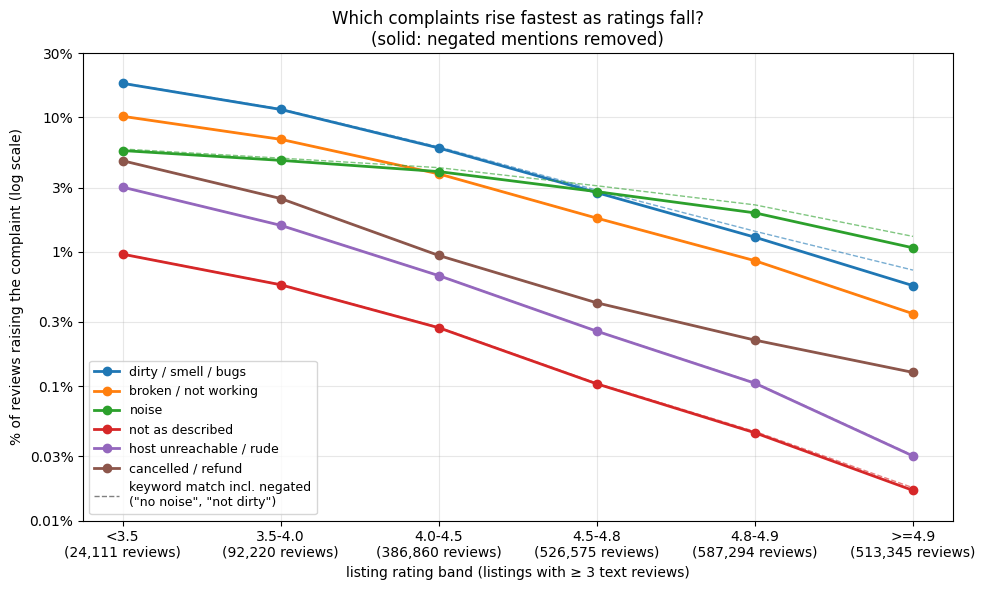

In [0]:
# 3a chart 2: share of reviews raising each complaint theme, by rating band (log scale to compare growth rates)
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(a3_theme))
for name in THEMES:
    line, = ax.plot(x, a3_theme[name] * 100, marker="o", lw=2, label=name)
    # dashed: plain keyword match before removing negations; it only separates visibly where negations are common
    ax.plot(x, a3_kw[name] * 100, ls="--", lw=1, alpha=0.6, color=line.get_color())
ax.plot([], [], ls="--", lw=1, color="grey", label="keyword match incl. negated\n(\"no noise\", \"not dirty\")")
ax.set_xticks(x, [f"{b.split(': ')[1]}\n({int(n):,} reviews)" for b, n in zip(a3_theme.index, a3_theme.reviews)])
ax.set_yscale("log")
ax.set_yticks([0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30], ["0.01%", "0.03%", "0.1%", "0.3%", "1%", "3%", "10%", "30%"])
ax.minorticks_off()
ax.set_xlabel("listing rating band (listings with ≥ 3 text reviews)")
ax.set_ylabel("% of reviews raising the complaint (log scale)")
ax.set_title("Which complaints rise fastest as ratings fall?\n(solid: negated mentions removed)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Assumptions and filtering (3a, chart 2):**

- filtering or sampling applied, and rows remaining: We kept listings with a positive rating and at least three text reviews, then grouped them into six rating bands. We kept all 5,604 rows below 3.5 and all 13,431 rows from 3.5 to below 4.0, and sampled about 30,000 rows from each of the other four bands, for about 139,000 listing rows overall
- Size of each group: From the lowest to the highest rating band, the samples contained 24,111, 92,220, 386,860, 526,575, 587,294, and 513,345 review texts

**What the chart shows:** On the logarithmic scale, each solid line shows the percentage of reviews matching a complaint theme after excluding phrases such as “not dirty,” and the dashed line of the same color shows the original keyword-only percentage. Dirt, smells, or bugs were the most common complaint in the lowest band (17.9% of reviews), while complaints about host conduct, inaccurate descriptions, and cancellations showed the largest proportional increases from the highest band to the lowest. Host complaints were about 100 times as common and inaccurate-description complaints about 57 times as common in the lowest band, partly because their highest-band shares were just 0.030% and 0.017%, respectively, while noise complaints differed by a factor of about 5.3

### Question 3b

How does the set of amenities offered differ between two groups of listings types that you choose to compare?

In [0]:
# 3b setup: two listing groups -- a whole place to yourself vs a room in someone's home
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import Window
from pyspark.sql.types import ArrayType, StringType

spark.conf.set("spark.databricks.execution.timeout", "900")  # same reason as in 3a

ROOM_TYPES = ["Room", "Private room", "Shared room"]
HOTEL_LIKE = r"(?i)hotel|hostel|resort|serviced apartment"  # "Room in hotel" etc.: a different product, left out

b3_all = (
    airbnb_df
    .where(F.col("category") == "Stays")  # English pages only (~99%): amenity names are then in one language
    .withColumn("ltype", F.regexp_extract("listing_name", r"^(.*?) in ", 1))
    .withColumn("desc0", F.get(F.from_json("description_items", ArrayType(StringType())), 0))
    .withColumn("hotel_like", F.coalesce(F.col("desc0").rlike(HOTEL_LIKE), F.lit(False)))
    .withColumn("group", F.when(F.col("ltype").startswith("Entire"), "entire place")
                          .when(F.col("ltype").isin(ROOM_TYPES) & ~F.col("hotel_like"), "room in a home"))
)
print("rows by group before filtering (None = other types, e.g. hotel rooms, tiny homes, tents):")
b3_all.groupBy("group").count().orderBy(F.desc("count")).show()
print("room-type rows left out as hotel-like:",
      b3_all.where(F.col("ltype").isin(ROOM_TYPES) & F.col("hotel_like")).count())

rows by group before filtering (None = other types, e.g. hotel rooms, tiny homes, tents):
+--------------+-------+
|         group|  count|
+--------------+-------+
|  entire place|1725668|
|room in a home| 230177|
|          NULL| 122166|
+--------------+-------+

room-type rows left out as hotel-like: 60339


In [0]:
# 3b amenity set per listing: available items only (Q1b's is_available rule), one key per amenity
# Brand / detail variants share an icon code (3,000+ different "TV" names), so those codes are merged by code.
BRAND_CODES = {
    "SYSTEM_TV": "tv", "SYSTEM_REFRIGERATOR": "refrigerator", "SYSTEM_COFFEE_MAKER": "coffee maker",
    "SYSTEM_SHAMPOO": "shampoo / conditioner", "SYSTEM_SOAP": "body soap", "SYSTEM_WASHER": "washer",
    "SYSTEM_DRYER": "dryer", "SYSTEM_STOVE": "stove", "SYSTEM_OVEN": "oven", "SYSTEM_WARDROBE": "clothes storage",
    "SYSTEM_GRILL": "bbq grill", "SYSTEM_POOL": "pool", "SYSTEM_FIREPLACE": "indoor fireplace",
    "SYSTEM_GYM": "exercise equipment / gym", "SYSTEM_PACK_N_PLAY": "travel crib", "SYSTEM_HIGH_CHAIR": "high chair",
    "SYSTEM_CLEAN": "housekeeping", "SYSTEM_CRIB": "crib", "SYSTEM_TOYS": "children's toys",
    "SYSTEM_JACUZZI": "hot tub", "SYSTEM_SPEAKERS": "sound system", "SYSTEM_VIDEO_GAME": "game console",
}
code_map = F.create_map(*[F.lit(x) for kv in BRAND_CODES.items() for x in kv])


def amenity_key(item):
    # "Free washer – In unit" -> "free washer", "Long-term stays allowed" -> "long term stays allowed"
    name = F.trim(F.lower(F.regexp_replace(F.regexp_replace(item["name"], r"\s+[–-]\s.*$", ""), "-", " ")))
    name = F.regexp_replace(name, "drop off", "dropoff")  # "Luggage drop-off" and "Luggage dropoff" both occur
    by_code = F.try_element_at(code_map, item["value"])
    return (F.when(by_code.isNotNull(), by_code)
             .when(name.rlike(r"^(fast )?wi ?fi"), F.lit("wifi"))  # "Fast wifi – 300 Mbps"
             .otherwise(name))


b3 = (
    b3_all.where(F.col("group").isNotNull() & F.col("amenities").isNotNull())
    .withColumn("amen_groups", F.from_json("amenities", amen_schema))  # amen_schema / is_available: from Q1b
    .withColumn("offered", F.array_distinct(F.flatten(F.transform("amen_groups", lambda g: F.transform(
        F.filter(g["items"], lambda i: is_available(g, i)), amenity_key)))))
    .withColumn("n_offered", F.coalesce(F.size("offered"), F.lit(0)))
)
b3_n = {r["group"]: r["count"] for r in b3.groupBy("group").count().collect()}
N_ENT, N_ROOM = b3_n["entire place"], b3_n["room in a home"]
print(f"entire place: {N_ENT:,} rows | room in a home: {N_ROOM:,} rows")

entire place: 1,725,668 rows | room in a home: 230,177 rows


In [0]:
# 3b prevalence: share of listings in each group that offer each amenity (one count per listing and amenity)
MIN_LISTINGS = 2000  # ignore amenities offered by fewer listings than this across both groups
TOP_K = 12

b3_prev = (
    b3.select("group", F.explode("offered").alias("amenity"))
    .groupBy("amenity").pivot("group", ["entire place", "room in a home"]).count().na.fill(0)
    .withColumnRenamed("entire place", "n_entire").withColumnRenamed("room in a home", "n_room")
    .where(F.col("n_entire") + F.col("n_room") >= MIN_LISTINGS)
    .withColumn("p_entire", F.col("n_entire") / N_ENT)
    .withColumn("p_room", F.col("n_room") / N_ROOM)
    .withColumn("diff_pp", (F.col("p_entire") - F.col("p_room")) * 100)  # percentage points
)
b3_top = (
    b3_prev
    .withColumn("r_ent", F.row_number().over(Window.orderBy(F.desc("diff_pp"), "amenity")))
    .withColumn("r_room", F.row_number().over(Window.orderBy("diff_pp", "amenity")))
    .where((F.col("r_ent") <= TOP_K) | (F.col("r_room") <= TOP_K))
    .toPandas().sort_values("diff_pp")
)
print(b3_top[["amenity", "n_entire", "n_room", "p_entire", "p_room", "diff_pp"]].round(3).to_string(index=False))
print("median distinct amenities offered:",
      {r["group"]: r["med"] for r in b3.groupBy("group").agg(F.percentile_approx("n_offered", 0.5).alias("med")).collect()})

/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


                              amenity  n_entire  n_room  p_entire  p_room  diff_pp
                 lock on bedroom door         0  130469     0.000   0.567  -56.682
              luggage dropoff allowed    365779   80125     0.212   0.348  -13.614
                            breakfast     34181   34934     0.020   0.152  -13.196
                      host greets you    274621   58691     0.159   0.255   -9.584
                  private living room         0   21219     0.000   0.092   -9.219
              shared patio or balcony     46190   24941     0.027   0.108   -8.159
                          mini fridge    161504   35022     0.094   0.152   -5.856
exterior security cameras on property    400743   65510     0.232   0.285   -5.238
                      smoking allowed    136409   29923     0.079   0.130   -5.095
                  dedicated workspace    812292  118610     0.471   0.515   -4.459
                        first aid kit    733093  105698     0.425   0.459   -3.439
    

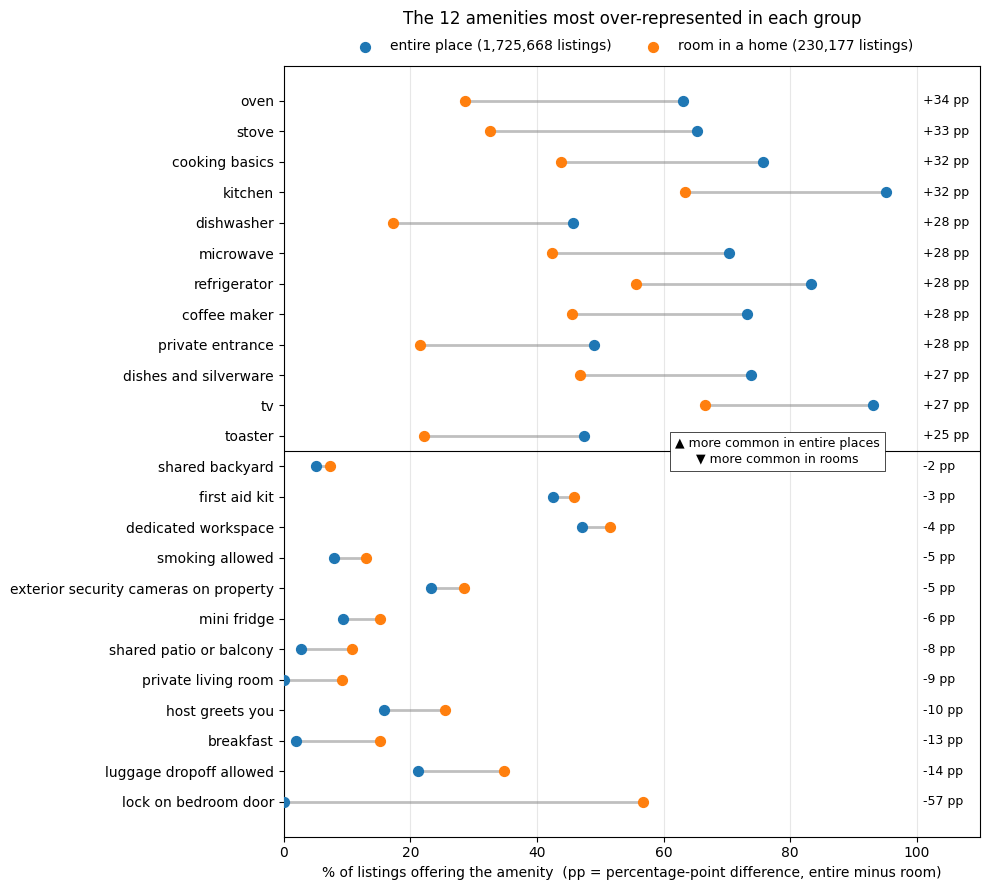

In [0]:
# 3b chart 1: the amenities whose availability differs most between the two groups
fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(b3_top))
ax.hlines(y, b3_top.p_room * 100, b3_top.p_entire * 100, color="grey", lw=2, alpha=0.5)
ax.scatter(b3_top.p_entire * 100, y, color="#1f77b4", s=50, zorder=3, label=f"entire place ({N_ENT:,} listings)")
ax.scatter(b3_top.p_room * 100, y, color="#ff7f0e", s=50, zorder=3, label=f"room in a home ({N_ROOM:,} listings)")
for yi, (_, r) in zip(y, b3_top.iterrows()):
    ax.text(101, yi, f"{r.diff_pp:+.0f} pp", va="center", fontsize=9)
ax.set_yticks(y, b3_top.amenity)
ax.axhline(TOP_K - 0.5, color="black", lw=0.8)
ax.text(78, TOP_K - 0.5, "▲ more common in entire places\n▼ more common in rooms", fontsize=9, va="center",
        ha="center", bbox=dict(facecolor="white", edgecolor="black", lw=0.5))
ax.set_xlim(0, 110)
ax.set_xlabel("% of listings offering the amenity  (pp = percentage-point difference, entire minus room)")
ax.set_title(f"The {TOP_K} amenities most over-represented in each group", pad=30)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

**Assumptions and filtering (3b):**

- The two groups being compared, and why they are worth comparing: We compare entire places with rooms in homes, identified from the listing type in listing_name, because these accommodation types may offer different balances of independent facilities and host interaction.
- Filtering or sampling applied, and rows remaining: We retain English “Stays” pages, exclude 60,339 hotel-like rooms and 122,166 other listing types, and apply the Q1b availability rule while merging amenity-name variants and counting each amenity once per listing, leaving 1,955,845 rows.
- Size of each group: Entire places: 1,725,668 rows; rooms in homes: 230,177 rows.

**What the chart shows:** Each dot represents the percentage of listings offering an amenity, and the connecting label gives the entire-place minus room difference in percentage points, showing the 12 largest gaps in each direction among amenities offered by at least 2,000 listings across the groups. Entire places more often provide cooking facilities, private entrances, and televisions, including gaps of approximately 34 percentage points for ovens and 32 for kitchens. Rooms more often offer bedroom locks, breakfast, luggage drop-off, and host greetings, although their advantages are generally smaller apart from bedroom locks, which have a 57-percentage-point gap

In [0]:
# 3b follow-up: rooms are cheaper -- is the amenity gap just price? Compare the groups within the same nightly price band.
# Nightly price as in 3c: pricing_details.price_per_night (the `price` field is sometimes a multi-night total), in USD.
PRICE_BANDS = [10, 50, 75, 100, 150, 200, 300, 500, 10000]
band_labels = [f"${lo}-{hi}" if hi < 10000 else f"${lo}+" for lo, hi in zip(PRICE_BANDS[:-1], PRICE_BANDS[1:])]
nightly = F.get_json_object("pricing_details", "$.price_per_night").try_cast("double")
price_usd = F.when(F.col("currency") == "USD", nightly).when(F.col("currency") == "EUR", nightly * 1.08)

band_expr = F.lit(None)
for lo, hi, lab in reversed(list(zip(PRICE_BANDS[:-1], PRICE_BANDS[1:], band_labels))):
    band_expr = F.when((F.col("price_usd") >= lo) & (F.col("price_usd") < hi), lab).otherwise(band_expr)

b3_priced = (b3.withColumn("price_usd", price_usd)
             .withColumn("price_band", band_expr)
             .where(F.col("price_band").isNotNull()))  # drops rows without a nightly USD/EUR price in 10-10,000
b3_by_price = (
    b3_priced.groupBy("price_band", "group")
    .agg(F.count("*").alias("listings"),
         F.percentile_approx("n_offered", [0.25, 0.5, 0.75], 1000).alias("q"),
         F.avg(F.array_contains("offered", "kitchen").cast("double")).alias("share_kitchen"),
         F.avg(F.array_contains("offered", "washer").cast("double")).alias("share_washer"),
         F.avg(F.array_contains("offered", "lock on bedroom door").cast("double")).alias("share_lock"))
    .toPandas()
)
b3_by_price[["q25", "median", "q75"]] = pd.DataFrame(b3_by_price.pop("q").tolist(), index=b3_by_price.index)
b3_by_price["price_band"] = pd.Categorical(b3_by_price.price_band, band_labels, ordered=True)
b3_by_price = b3_by_price.sort_values(["group", "price_band"])
print(f"rows with a nightly price: {b3_by_price.listings.sum():,}",
      {g: int(n) for g, n in b3_by_price.groupby("group").listings.sum().items()})
print(b3_by_price.round(3).to_string(index=False))

rows with a nightly price: 1,349,160 {'entire place': 1195309, 'room in a home': 153851}
price_band          group  listings  share_kitchen  share_washer  share_lock  q25  median  q75
    $10-50   entire place    108188          0.909         0.543       0.000   17      28   37
    $50-75   entire place    124596          0.927         0.611       0.000   21      32   40
   $75-100   entire place    142993          0.934         0.667       0.000   25      35   44
  $100-150   entire place    243878          0.950         0.728       0.000   27      37   46
  $150-200   entire place    169153          0.962         0.784       0.000   29      39   49
  $200-300   entire place    184410          0.973         0.830       0.000   30      41   51
  $300-500   entire place    135137          0.979         0.880       0.000   31      42   53
     $500+   entire place     86954          0.979         0.909       0.000   30      42   55
    $10-50 room in a home     61826          0.698      

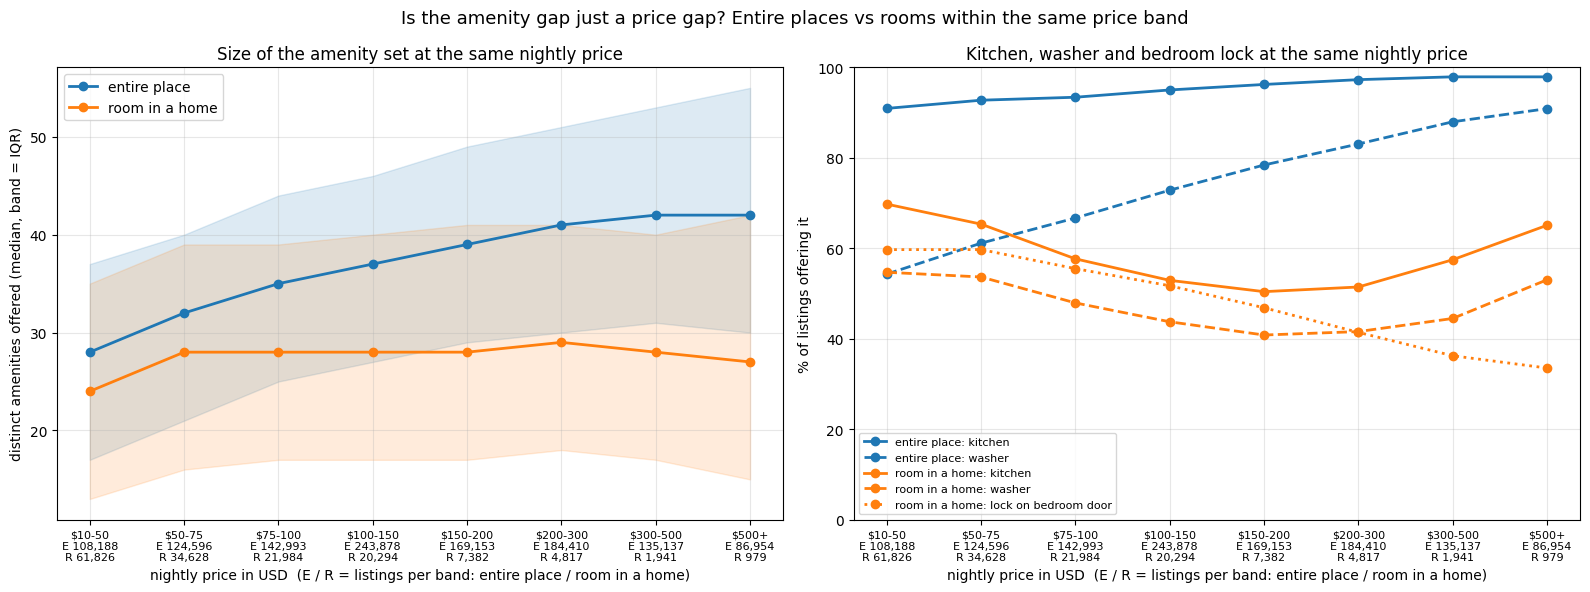

In [0]:
# 3b chart 2: amenity count and three marker amenities by nightly price band, per group
colors_b = {"entire place": "#1f77b4", "room in a home": "#ff7f0e"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(band_labels))
for g, d in b3_by_price.groupby("group"):
    d = d.set_index("price_band").reindex(band_labels)
    axes[0].plot(x, d["median"], marker="o", lw=2, color=colors_b[g], label=g)
    axes[0].fill_between(x, d.q25, d.q75, color=colors_b[g], alpha=0.15)
    markers = [("share_kitchen", "-", "kitchen"), ("share_washer", "--", "washer")]
    if g == "room in a home":  # an entire place cannot have a lock on a bedroom door (always 0%), so only rooms
        markers.append(("share_lock", ":", "lock on bedroom door"))
    for col, ls, lab in markers:
        axes[1].plot(x, d[col] * 100, ls=ls, marker="o", lw=2, color=colors_b[g], label=f"{g}: {lab}")
axes[0].set_ylabel("distinct amenities offered (median, band = IQR)")
axes[0].set_title("Size of the amenity set at the same nightly price")
axes[1].set_ylabel("% of listings offering it")
axes[1].set_title("Kitchen, washer and bedroom lock at the same nightly price")
axes[1].set_ylim(0, 100)
axes[1].legend(fontsize=8, loc="lower left")
axes[0].legend()
counts = b3_by_price.pivot(index="price_band", columns="group", values="listings").reindex(band_labels)
for ax in axes:
    ax.set_xticks(x, [f"{b}\nE {int(counts.loc[b, 'entire place']):,}\nR {int(counts.loc[b, 'room in a home']):,}"
                      for b in band_labels], fontsize=8)
    ax.set_xlabel("nightly price in USD  (E / R = listings per band: entire place / room in a home)")
    ax.grid(alpha=0.3)
fig.suptitle("Is the amenity gap just a price gap? Entire places vs rooms within the same price band", fontsize=13)
fig.tight_layout()
plt.show()

**Assumptions and filtering (3b, chart 2):**

- Filtering or sampling applied, and rows remaining: we retain the same accommodation groups but require a nightly price from price_per_night between \$10 and \$10,000 after converting EUR to USD at a fixed factor of 1.08, using this field because price represents the whole stay in 42,950 rows
- Size of each group: The filtered dataset contains 1,349,160 rows: 1,195,309 entire places and 153,851 rooms, with the E/R labels showing counts within each price band

**What the chart shows:** The two panels jointly examine whether amenity differences remain within comparable price bands, using total amenity counts in one panel and selected amenities in the other. Entire places retain higher median amenity counts, with the gap increasing from 28 versus 24 in the \$10–50 band to 42 versus 27 in the \$500+ band, suggesting that broad price differences alone do not account for the observed pattern. Rooms also show lower bedroom-lock availability in the highest band, but the upper room bands contain only 1,941 and 979 rows, so their patterns warrant caution

### Question 3c

Your own question, answered with a visualization.

**Our question:** Across cities in the USA, Europe, Asia, and Latin America, how does the number of distinct Airbnb properties, used as a measure of competition, relate to nightly prices per guest relative to the country median and to the share of rated listings scoring at least 4.9?

**Why it is worth asking:** Understanding whether more crowded Airbnb markets are associated with cheaper stays or different guest ratings could inform guests’ choices, hosts’ market-entry decisions, and regulators’ assessments, while comparing regions tests whether the relationships extend beyond a single market

In [0]:
# 3c setup: city / country / region keys, price per guest in USD, rating
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import Window
from pyspark.sql.types import ArrayType, StringType, StructType, StructField

# `location` is "City, Region, Country"; ~1% of rows write the country in German (or French).
COUNTRY_FIX = {
    "Vereinigte Staaten": "United States", "États-Unis": "United States", "Frankreich": "France",
    "Italien": "Italy", "Brasilien": "Brazil", "Spanien": "Spain", "Vereinigtes Königreich": "United Kingdom",
    "Mexiko": "Mexico", "Deutschland": "Germany", "Kanada": "Canada", "Griechenland": "Greece",
    "Australien": "Australia", "Kroatien": "Croatia", "Kolumbien": "Colombia", "Philippinen": "Philippines",
    "Indien": "India", "Südkorea": "South Korea", "Türkei": "Turkey", "Argentinien": "Argentina",
    "Polen": "Poland", "Südafrika": "South Africa", "Norwegen": "Norway", "Schweden": "Sweden",
    "Dänemark": "Denmark", "Niederlande": "Netherlands", "Neuseeland": "New Zealand", "Marokko": "Morocco",
    "Schweiz": "Switzerland", "Österreich": "Austria", "Dominikanische Republik": "Dominican Republic",
    "Belgien": "Belgium", "Irland": "Ireland", "Rumänien": "Romania", "Ungarn": "Hungary",
    "Georgien": "Georgia", "Finnland": "Finland", "Vereinigte Arabische Emirate": "United Arab Emirates",
    "Tschechien": "Czechia", "Ägypten": "Egypt", "Albanien": "Albania", "Indonesien": "Indonesia",
    "Slowenien": "Slovenia", "Bulgarien": "Bulgaria", "Kenia": "Kenya", "Serbien": "Serbia", "Kuba": "Cuba",
    "Island": "Iceland", "Jamaika": "Jamaica", "Zypern": "Cyprus", "Saudi-Arabien": "Saudi Arabia",
}

# Regions follow the UN M49 grouping (so Turkey, Cyprus and the Caucasus are in Asia).
# Countries not listed (Canada, Oceania, Africa, small territories) fall into "Other".
REGIONS = {
    "USA": ["United States"],
    "Europe": [
        "France", "Italy", "Spain", "United Kingdom", "Greece", "Germany", "Portugal", "Croatia", "Poland",
        "Norway", "Sweden", "Denmark", "Netherlands", "Switzerland", "Austria", "Belgium", "Ireland", "Czechia",
        "Romania", "Finland", "Hungary", "Russia", "Albania", "Montenegro", "Bulgaria", "Ukraine", "Serbia",
        "Malta", "Slovenia", "Iceland", "Slovakia", "Bosnia & Herzegovina", "Lithuania", "Estonia", "Latvia",
        "North Macedonia", "Moldova", "Luxembourg", "Kosovo", "Faroe Islands", "Andorra", "Belarus",
        "Isle of Man", "Jersey", "Guernsey", "Gibraltar", "Monaco",
    ],
    "Asia": [
        "India", "Thailand", "South Korea", "Philippines", "Malaysia", "Turkey", "Japan", "Vietnam",
        "United Arab Emirates", "Israel", "Georgia", "Saudi Arabia", "Taiwan", "Sri Lanka", "Cyprus", "Lebanon",
        "Pakistan", "Kazakhstan", "Armenia", "Hong Kong", "Jordan", "Cambodia", "Azerbaijan", "Nepal",
        "Uzbekistan", "Oman", "Singapore", "Kyrgyzstan", "Maldives", "Bangladesh", "Bahrain", "Mongolia",
        "Laos", "Qatar", "Indonesia", "Iraq", "Kuwait", "Tajikistan", "Brunei",
    ],
    "Latin America": [
        "Brazil", "Mexico", "Colombia", "Argentina", "Chile", "Costa Rica", "Peru", "Dominican Republic",
        "Ecuador", "Puerto Rico", "Uruguay", "Guatemala", "Cuba", "Jamaica", "Panama", "El Salvador", "Bolivia",
        "Honduras", "Venezuela", "Paraguay", "Nicaragua", "Belize",
    ],
}
REGION_ORDER = ["USA", "Europe", "Asia", "Latin America", "Other"]
PLOT_REGIONS = REGION_ORDER[:4]  # "Other" mixes Canada, Africa and Oceania (23 cities): too mixed to read as one group

# The same city is split under several names; merge the two big cases.
NYC_BOROUGHS = ["Brooklyn", "Manhattan", "Queens", "Bronx", "The Bronx", "Staten Island"]

fix_map = F.create_map(*[F.lit(x) for kv in COUNTRY_FIX.items() for x in kv])
region_map = F.create_map(*[F.lit(x) for r, cs in REGIONS.items() for c in cs for x in (c, r)])
loc_parts = F.split(F.col("location"), ", ")

c3 = (
    airbnb_df
    .where(F.size(loc_parts) >= 2)  # need at least "city, country"
    .withColumn("country_raw", F.trim(F.element_at(loc_parts, -1)))
    .withColumn("country", F.coalesce(F.try_element_at(fix_map, F.col("country_raw")), F.col("country_raw")))
    .withColumn("city", F.trim(loc_parts[0]))
    .withColumn("city", F.when((F.col("country") == "United Kingdom") & (F.col("city") == "Greater London"), "London")
                         .when((F.col("country") == "United States") & F.col("city").isin(NYC_BOROUGHS), "New York")
                         .otherwise(F.col("city")))
    .withColumn("region", F.coalesce(F.try_element_at(region_map, F.col("country")), F.lit("Other")))
    .withColumn("rating", F.col("ratings").try_cast("double"))
    .withColumn("guests_n", F.col("guests").try_cast("int"))
    # `price` is the total of the searched stay when the scrape searched many nights (e.g. 30-night
    # searches in New York), so we use the nightly price from pricing_details instead (see check below)
    .withColumn("nightly", F.get_json_object("pricing_details", "$.price_per_night").try_cast("double"))
    .withColumn("search_nights", F.get_json_object("pricing_details", "$.num_of_nights").try_cast("int"))
    # same USD rule as Q1b: USD unchanged, EUR x 1.08, anything else (null currency) -> null
    .withColumn("price_usd", F.when(F.col("currency") == "USD", F.col("nightly"))
                              .when(F.col("currency") == "EUR", F.col("nightly") * 1.08))
    # price per guest removes most of the "big villas vs studios" difference between cities
    .withColumn("ppg", F.col("price_usd") / F.col("guests_n"))
)

# Why not `price`: how often it is far above the nightly price, and for which search lengths
p_raw = F.col("price").try_cast("double")
inflated = c3.where(p_raw > 1.5 * F.col("nightly"))
print(f"rows where price > 1.5 x price_per_night: {inflated.count():,}")
inflated.groupBy("search_nights").count().orderBy(F.desc("count")).show(5)
c3.where(F.col("city") == "New York").select(
    F.percentile_approx(p_raw, 0.5).alias("median_price_field"),
    F.percentile_approx("nightly", 0.5).alias("median_price_per_night")).show()

rows where price > 1.5 x price_per_night: 42,950
+-------------+-----+
|search_nights|count|
+-------------+-----+
|           30|16659|
|           31| 8955|
|           28| 4006|
|           15| 3962|
|          100| 3300|
+-------------+-----+
only showing top 5 rows
+------------------+----------------------+
|median_price_field|median_price_per_night|
+------------------+----------------------+
|            2395.0|                 179.0|
+------------------+----------------------+



In [0]:
# 3c aggregation: one row per city with >= MIN_PROPS distinct properties
MIN_PROPS = 500          # enough listings for a stable median and rating share
PRICE_RANGE = (10, 10000)  # nightly USD; outside this is almost always a scraping artefact (e.g. price=3)
KEYS = ["region", "country", "city"]

# rows are kept as independent records (no de-duplication); competition = distinct properties in the city
priced = c3.where(F.col("price_usd").between(*PRICE_RANGE) & (F.col("guests_n") >= 1))
rated = c3.where(F.col("rating") > 0)  # ratings == 0 is the placeholder for listings with no reviews

country_price = priced.groupBy("country").agg(F.percentile_approx("ppg", 0.5, 10000).alias("country_med_ppg"))

cities_sdf = (
    c3.groupBy(KEYS).agg(F.countDistinct("property_id").alias("n_props"), F.count("*").alias("n_rows"))
    .where(F.col("n_props") >= MIN_PROPS)
    .join(priced.groupBy(KEYS).agg(F.percentile_approx("ppg", 0.5, 10000).alias("city_med_ppg"),
                                   F.count("*").alias("n_priced_rows")), KEYS, "left")
    .join(rated.groupBy(KEYS).agg(F.avg((F.col("rating") >= 4.9).cast("double")).alias("share_top"),
                                  F.avg("rating").alias("mean_rating"),
                                  F.count("*").alias("n_rated_rows")), KEYS, "left")
    .join(country_price, "country", "left")
    .withColumn("rel_price", F.col("city_med_ppg") / F.col("country_med_ppg"))
)

# Spearman correlation per region (rank correlation, robust to the long tail of n_props)
region_rank = lambda c: Window.partitionBy("region").orderBy(c)
spearman = (
    cities_sdf
    .withColumn("r_n", F.rank().over(region_rank("n_props")))
    .withColumn("r_price", F.rank().over(region_rank("rel_price")))
    .withColumn("r_top", F.rank().over(region_rank("share_top")))
    .groupBy("region").agg(F.count("*").alias("n_cities"),
                           F.sum("n_rows").alias("rows_covered"),
                           F.corr("r_n", "r_price").alias("rho_price"),
                           F.corr("r_n", "r_top").alias("rho_top"))
)

print(f"rows with city+country: {c3.count():,} | priced rows: {priced.count():,} | rated rows: {rated.count():,}")
cities = cities_sdf.toPandas()   # already aggregated: one row per city
rho = spearman.toPandas().set_index("region").reindex(REGION_ORDER)
print(f"cities with >= {MIN_PROPS} properties: {len(cities)}, covering {cities.n_rows.sum():,} rows")
# printed as text (not display) so the tables survive the HTML export
print(rho.round(3).to_string())
print(cities.sort_values("n_props", ascending=False).head(15).round(3).to_string(index=False))

rows with city+country: 2,095,768 | priced rows: 1,431,602 | rated rows: 1,896,656
cities with >= 500 properties: 465, covering 679,420 rows
               n_cities  rows_covered  rho_price  rho_top
region                                                   
USA                 174        297264      0.030   -0.317
Europe              129        184929      0.139   -0.189
Asia                 52         58061      0.052    0.030
Latin America        87        109253      0.044   -0.045
Other                23         29913      0.381    0.285
             country        region           city  n_props  n_rows  city_med_ppg  n_priced_rows  share_top  mean_rating  n_rated_rows  country_med_ppg  rel_price
              France        Europe          Paris    13693   14731        70.328         7375.0      0.431        4.749         13513           31.750      2.215
      United Kingdom        Europe         London    13363   14154        64.000         7779.0      0.418        4.698         1

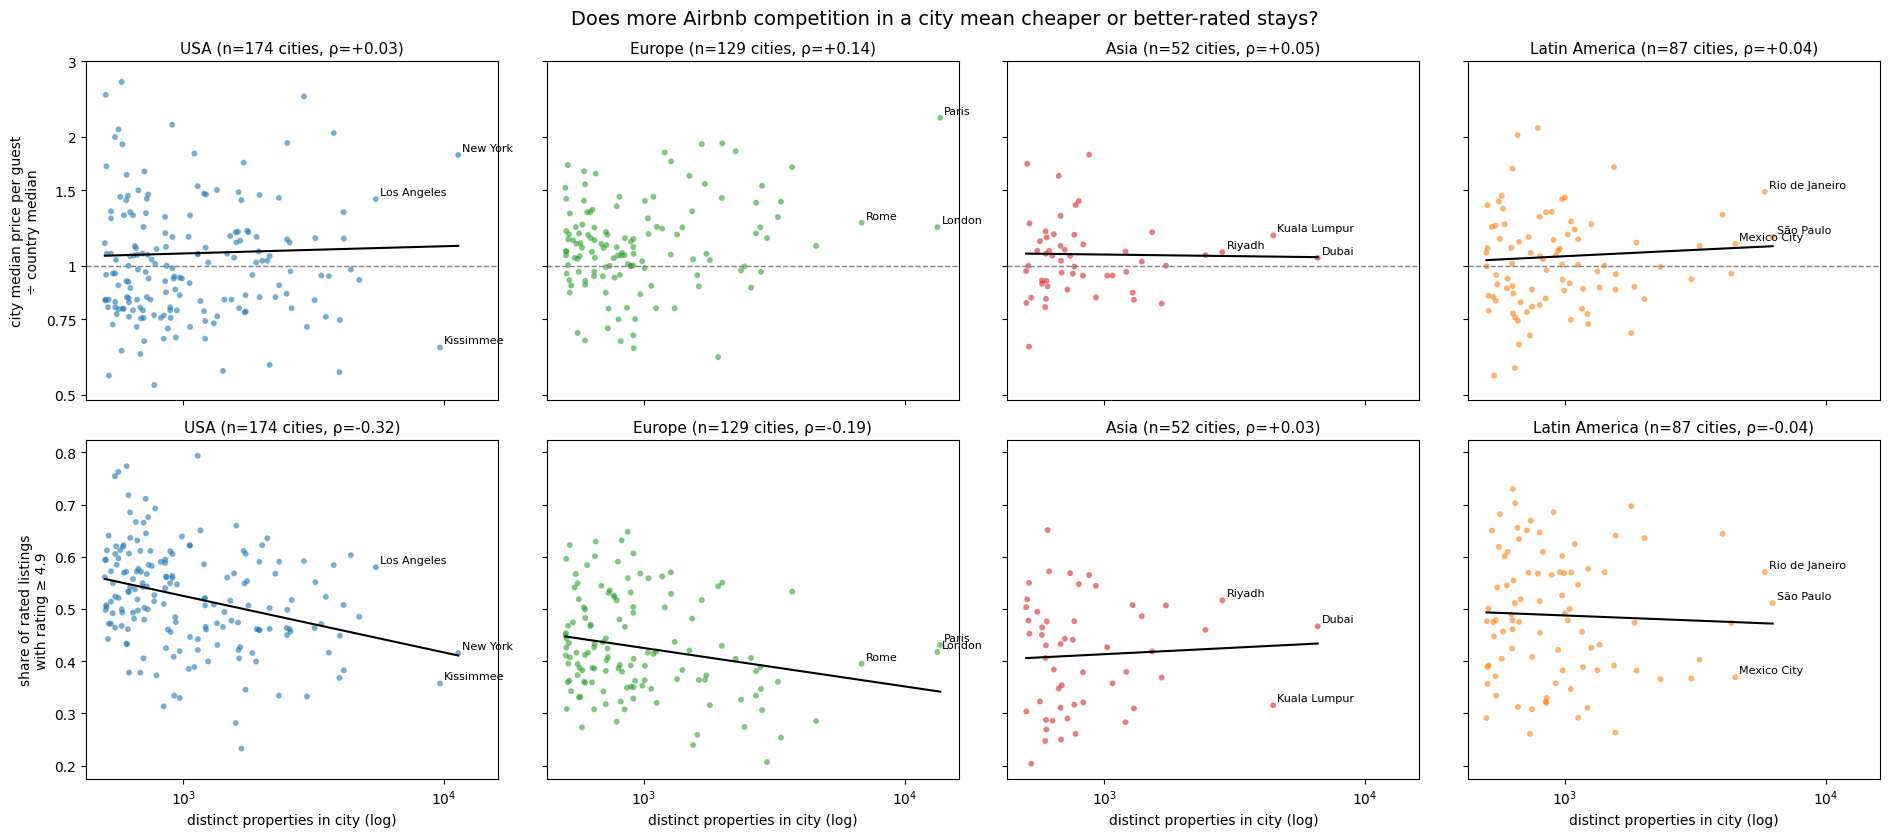

In [0]:
# 3c chart 1: competition vs relative price (top row) and vs share of top-rated listings (bottom row)
colors = dict(zip(PLOT_REGIONS, ["#1f77b4", "#2ca02c", "#d62728", "#ff7f0e"]))
fig, axes = plt.subplots(2, 4, figsize=(19, 8.5), sharex=True, sharey="row")
for j, region in enumerate(PLOT_REGIONS):
    d = cities[cities.region == region]
    for i, (col, rho_col) in enumerate([("rel_price", "rho_price"), ("share_top", "rho_top")]):
        ax = axes[i, j]
        ax.scatter(d.n_props, d[col], s=18, alpha=0.6, color=colors[region], edgecolor="none")
        if len(d) > 2:  # least-squares trend on log10(n_props), drawn only as a visual guide
            k, b = np.polyfit(np.log10(d.n_props), d[col], 1)
            xs = np.logspace(np.log10(d.n_props.min()), np.log10(d.n_props.max()), 50)
            ax.plot(xs, k * np.log10(xs) + b, color="black", lw=1.5)
        for _, r in d.nlargest(3, "n_props").iterrows():
            ax.annotate(r.city, (r.n_props, r[col]), fontsize=8, xytext=(3, 3), textcoords="offset points")
        ax.set_xscale("log")
        ax.set_title(f"{region} (n={len(d)} cities, ρ={rho.loc[region, rho_col]:+.2f})", fontsize=11)
        if i == 0:
            ax.axhline(1, color="grey", ls="--", lw=1)
axes[0, 0].set_ylabel("city median price per guest\n÷ country median")
axes[1, 0].set_ylabel("share of rated listings\nwith rating ≥ 4.9")
for ax in axes[1]:
    ax.set_xlabel("distinct properties in city (log)")
axes[0, 0].set_yscale("log")
axes[0, 0].set_yticks([0.5, 0.75, 1, 1.5, 2, 3], ["0.5", "0.75", "1", "1.5", "2", "3"])
axes[0, 0].minorticks_off()
fig.suptitle("Does more Airbnb competition in a city mean cheaper or better-rated stays?", fontsize=14)
fig.tight_layout()
plt.show()

**Assumptions and filtering (3c):**

- Filtering or sampling applied, and rows remaining: Starting with 2,095,768 rows containing city and country, we calculate prices from 1,431,602 rows with nightly USD prices of \$10–10,000 and at least one guest and rating shares from 1,896,656 rows with ratings above 0, define relative price as the city median price per guest per night divided by the country median and the rating measure as the share of rated listings scoring ≥ 4.9, and retain cities with at least 500 distinct properties to support more stable summaries, yielding 465 cities covering 679,420 rows.

**What the chart shows:** Each dot represents a city and each trend line summarizes the association; the eight panels form one comparison because the columns repeat it across regions and the two rows address its price and rating components, covering 174 USA, 129 European, 52 Asian, and 87 Latin American cities, with 23 “Other” cities omitted. Spearman correlations with relative price are weak in every region (USA +0.03, Europe +0.14, Asia +0.05, Latin America +0.04), whereas correlations with the share of top ratings are negative and marked significant in the USA (−0.32) and Europe (−0.19), but near zero in Asia (+0.03) and Latin America (−0.04). These are associations between cities and do not establish that greater competition changes prices or ratings

In [0]:
# 3c follow-up: what else changes with competition? Per-city mix and category ratings, again one row per city
CATS = ["Cleanliness", "Accuracy", "Check-in", "Communication", "Location", "Value"]  # English names only
cat_schema_3c = ArrayType(StructType([StructField("name", StringType()), StructField("value", StringType())]))
cat_val = lambda name: F.get(F.transform(F.filter("cats", lambda c: c["name"] == name),
                                          lambda c: F.regexp_replace(c["value"], ",", ".").try_cast("double")), 0)

seller = F.get_json_object("seller_info", "$.seller_id")
# host size = distinct properties the host has in the dataset (one row per seller, so the join adds no rows)
host_size = (airbnb_df.where(seller.isNotNull()).groupBy(seller.alias("seller_id"))
             .agg(F.countDistinct("property_id").alias("host_props")))

c3x = (
    c3.withColumn("seller_id", seller)
    .join(host_size, "seller_id", "left")
    .withColumn("cats", F.from_json("category_rating", cat_schema_3c))
    .select(*KEYS, "rating", "host_props", "is_supperhost", "listing_name",
            *[cat_val(c).alias(c) for c in CATS])
)
assert c3x.count() == c3.count(), "host join must not add rows"
mix = (
    c3x.groupBy(KEYS).agg(
        *[F.avg(c).alias(c) for c in CATS],  # avg ignores rows without that category
        F.avg((F.col("host_props") >= 10).cast("double")).alias("share_pro_host"),
        F.avg((F.col("is_supperhost") == "true").cast("double")).alias("share_superhost"),
        F.avg(F.col("listing_name").startswith("Entire").cast("double")).alias("share_entire_place"),
    )
    .join(cities_sdf.select(*KEYS, "n_props", "share_top", "rel_price"), KEYS, "inner")  # keep the same cities as chart 1
)

METRICS = {"rel_price": "relative price per guest", "share_top": "share rated ≥ 4.9",
           **{c: f"{c} rating" for c in CATS},
           "share_superhost": "share superhost listings", "share_pro_host": "share from hosts with ≥10 listings",
           "share_entire_place": "share entire places"}
rmix = mix.withColumn("r_n", F.rank().over(region_rank("n_props")))
for m in METRICS:
    rmix = rmix.withColumn(f"r_{m}", F.rank().over(region_rank(m)))
rho_mix = (rmix.where(F.col("region").isin(PLOT_REGIONS)).groupBy("region")
           .agg(F.count("*").alias("n_cities"), *[F.corr("r_n", f"r_{m}").alias(m) for m in METRICS])
           .toPandas().set_index("region").reindex(PLOT_REGIONS))
print(rho_mix.round(3).to_string())

               n_cities  rel_price  share_top  Cleanliness  Accuracy  Check-in  Communication  Location  Value  share_superhost  share_pro_host  share_entire_place
region                                                                                                                                                             
USA                 174      0.030     -0.317       -0.285    -0.306    -0.348         -0.295    -0.242 -0.226           -0.195           0.192               0.000
Europe              129      0.139     -0.189       -0.051    -0.109    -0.083         -0.121    -0.134 -0.068            0.076           0.101              -0.110
Asia                 52      0.052      0.030        0.079     0.052     0.029         -0.006     0.191  0.076            0.150           0.080               0.215
Latin America        87      0.044     -0.045       -0.045    -0.102    -0.064         -0.162    -0.085 -0.162            0.009           0.214               0.016


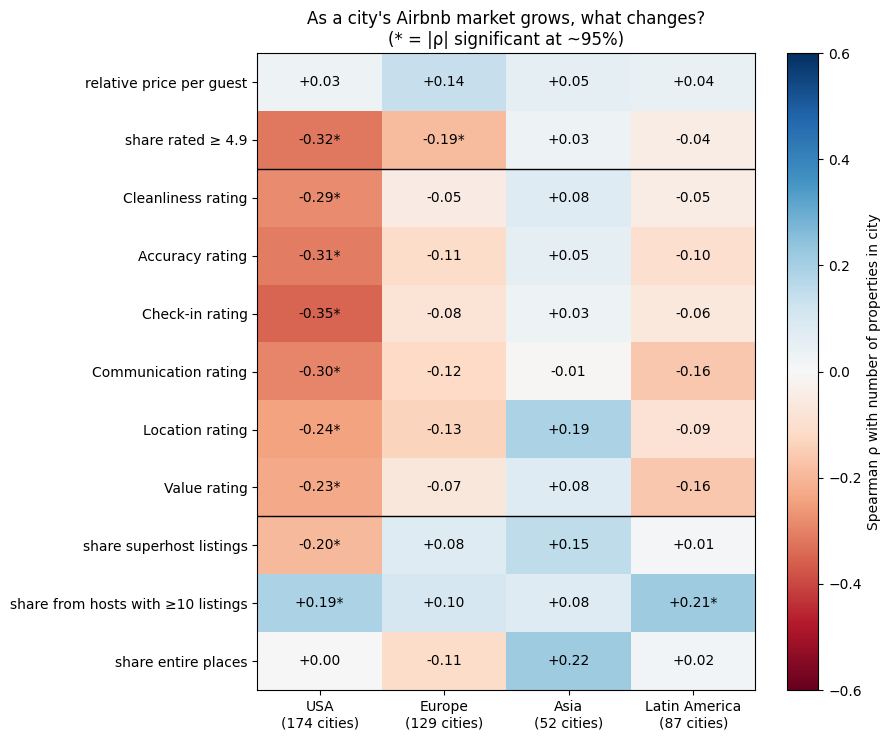

In [0]:
# 3c chart 2: heatmap of Spearman rho between city size and each city-level metric, per region
mat = rho_mix[list(METRICS)].T
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(mat.values, cmap="RdBu", vmin=-0.6, vmax=0.6, aspect="auto")
for i in range(mat.shape[0]):
    for j, region in enumerate(mat.columns):
        v = mat.iloc[i, j]
        sig = abs(v) > 1.96 / np.sqrt(rho_mix.loc[region, "n_cities"] - 1)  # approx. 95% test for rho = 0
        ax.text(j, i, f"{v:+.2f}{'*' if sig else ''}", ha="center", va="center", fontsize=10,
                color="white" if abs(v) > 0.4 else "black")
ax.set_xticks(range(len(mat.columns)), [f"{r}\n({int(rho_mix.loc[r, 'n_cities'])} cities)" for r in mat.columns])
ax.set_yticks(range(len(mat.index)), [METRICS[m] for m in mat.index])
ax.axhline(1.5, color="black", lw=1); ax.axhline(7.5, color="black", lw=1)
fig.colorbar(im, ax=ax, label="Spearman ρ with number of properties in city")
ax.set_title("As a city's Airbnb market grows, what changes?\n(* = |ρ| significant at ~95%)")
fig.tight_layout()
plt.show()

**Assumptions and filtering (3c, chart 2):**

- Filtering or sampling applied, and rows remaining: We use the same 465-city dataset with one row per city and display the same four regions, adding city-level category ratings and shares of superhosts, professional hosts—defined as sellers with at least 10 distinct properties—and entire-place listings.

**What the chart shows:** Following the rating pattern in chart 1, each heatmap cell reports the within-region Spearman correlation between city property count and another measure, with an asterisk indicating that it passes the stated approximate significance threshold, |ρ| > 1.96/√(n−1). In the USA, larger markets have lower ratings across all six categories (ρ from −0.23 to −0.35), a lower superhost share (−0.20), and a higher professional-host share (+0.19), while entire-place share has essentially no association with market size (0.00). Europe has no individually significant category-rating correlations despite its significant overall top-rating relationship, and Asia’s smaller sample limits the strength of conclusions; the USA pattern is consistent with differences in hosting composition, but does not establish an explanation for the rating decline

## Question 4 Evidence

The written report goes in `q4.pdf`. This section holds only the code that produced the numbers and examples you cite there. Every number in your report must be reproducible from a cell below.

### 4a, problem 1

**Problem:** multi-night stay totals stored in price

In [0]:
p_raw = F.col("price").try_cast("double")
nightly = F.get_json_object("pricing_details", "$.price_per_night").try_cast("double")
nights = F.get_json_object("pricing_details", "$.num_of_nights").try_cast("int")

priced_cmp = airbnb_df.withColumn("p_raw", p_raw).withColumn("nightly", nightly).withColumn("nights", nights)
discrepant = priced_cmp.where(F.col("p_raw").isNotNull() & F.col("nightly").isNotNull() & (F.col("p_raw") > 1.5 * F.col("nightly")))

# Summary counts and top stay lengths where `price` exceeds 1.5x per-night price
print("rows with both price and price_per_night:", priced_cmp.where(F.col("p_raw").isNotNull() & F.col("nightly").isNotNull()).count())
print("rows where price > 1.5 * price_per_night:", discrepant.count())
discrepant.groupBy("nights").count().orderBy(F.desc("count")).show(5, truncate=False)

# Concrete example row and naive vs. per-night median comparison for New York
discrepant.where(F.col("location").startswith("New York,")).select(
    "property_id", "location", "currency", "price", "nightly", "nights"
).show(3, truncate=False)

airbnb_df.where(F.col("location").startswith("New York,")).select(
    F.percentile_approx(p_raw, 0.5).alias("naive_median_price"),
    F.percentile_approx(nightly, 0.5).alias("median_price_per_night"),
).show(truncate=False)

rows with both price and price_per_night: 1445950
rows where price > 1.5 * price_per_night: 42979
+------+-----+
|nights|count|
+------+-----+
|30    |16671|
|31    |8959 |
|28    |4008 |
|15    |3962 |
|100   |3305 |
+------+-----+
only showing top 5 rows
+-------------------+-----------------------+--------+-------+-------+------+
|property_id        |location               |currency|price  |nightly|nights|
+-------------------+-----------------------+--------+-------+-------+------+
|1015168578871804091|New York, United States|USD     |7392   |195.0  |30    |
|7205064            |New York, United States|USD     |1480.18|65.0   |30    |
|7679697            |New York, United States|USD     |6349.47|180.17 |30    |
+-------------------+-----------------------+--------+-------+-------+------+
only showing top 3 rows
+------------------+----------------------+
|naive_median_price|median_price_per_night|
+------------------+----------------------+
|3080.0            |238.0                

### 4a, problem 2

**Problem:** multilingual and localization leakage across structured fields

In [0]:
cat_schema_q4 = ArrayType(StructType([
    StructField("name", StringType()),
    StructField("value", StringType()),
]))
de_fr_countries = ["Vereinigte Staaten", "États-Unis", "Frankreich", "Italien", "Deutschland", "Spanien"]

loc_country = F.trim(F.element_at(F.split(F.col("location"), ", "), -1))
cats_parsed = F.from_json("category_rating", cat_schema_q4)
has_comma_val = F.exists(cats_parsed, lambda c: c["value"].contains(",") & c["value"].rlike(r"^\d+,\d+$"))

print("rows with localized DE/FR country name:", airbnb_df.where(loc_country.isin(de_fr_countries)).count())
print("rows with comma-decimal category rating:", airbnb_df.where(has_comma_val).count())

# Concrete example and naive vs. comma-normalized parse count for category ratings
airbnb_df.where(has_comma_val).select("property_id", "location", "category_rating").show(2, truncate=False)

exploded_vals = airbnb_df.select(F.explode(cats_parsed).alias("c")).select(F.col("c.value").alias("raw_val"))
print("parsed numeric ratings (naive dot cast vs. comma->dot):",
      exploded_vals.where(F.col("raw_val").try_cast("double").isNotNull()).count(),
      exploded_vals.where(F.regexp_replace("raw_val", ",", ".").try_cast("double").isNotNull()).count())



rows with localized DE/FR country name: 9784
rows with comma-decimal category rating: 18040
+-------------------+---------------------------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|property_id        |location                                     |category_rating                                                                                                                                                                                                                                  |
+-------------------+---------------------------------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

### 4a, problem 3

**Problem:** Repeated property snapshots with time-varying state

In [0]:

prop_dups = (
    airbnb_df.where(F.col("property_id").isNotNull())
    .groupBy("property_id")
    .agg(
        F.count("*").alias("n_rows"),
        F.countDistinct("ratings").alias("n_distinct_ratings"),
        F.countDistinct("price").alias("n_distinct_prices"),
    )
)

print("duplicate property_ids (>1 row):", prop_dups.where(F.col("n_rows") > 1).count())
print("properties with varying ratings across rows:", prop_dups.where(F.col("n_distinct_ratings") > 1).count())
print("properties with varying price across rows:", prop_dups.where(F.col("n_distinct_prices") > 1).count())

# Concrete example of a property with multiple rows and differing values
sample_pid = prop_dups.where(F.col("n_distinct_prices") > 1).select("property_id").limit(1).collect()[0]["property_id"]
airbnb_df.where(F.col("property_id") == sample_pid).select("property_id", "ratings", "price", "currency").show(5, truncate=False)

# Naive row-level mean rating vs. distinct-property mean rating (excluding 0 sentinel)
rated_rows = airbnb_df.withColumn("r", F.col("ratings").try_cast("double")).where(F.col("r") > 0)
print("mean rating (all rated rows vs. one per property_id):",
      rated_rows.agg(F.avg("r")).collect()[0][0],
      rated_rows.groupBy("property_id").agg(F.avg("r").alias("p_r")).agg(F.avg("p_r")).collect()[0][0])


duplicate property_ids (>1 row): 181222
properties with varying ratings across rows: 28499
properties with varying price across rows: 90901
+------------------+-------+-----+--------+
|property_id       |ratings|price|currency|
+------------------+-------+-----+--------+
|740760693734080294|0      |52   |USD     |
|740760693734080294|0      |59.55|USD     |
+------------------+-------+-----+--------+

mean rating (all rated rows vs. one per property_id): 4.779691329975843 4.776201652858094


### 4b: simple supporting evidence for your research question

**Research question:**

In [0]:
print(rho_mix.loc["USA", ["n_cities", "share_top", "share_superhost", "share_pro_host"]].round(3))




n_cities           174.000
share_top           -0.317
share_superhost     -0.195
share_pro_host       0.192
Name: USA, dtype: float64
